# EDA: метки, пациенты, качество снимков, камеры и аугментации

Содержание:
1. **Метки** - метки глаз из keywords, баланс классов, сочетания болезней, один или оба глаза, шум от копирования меток пациента на глаза, класс O, левый и правый глаз.
2. **Пациенты** - возраст, пол, связь возраста и пола с классами.
3. **Качество снимков** - плохие снимки (открытый вопрос: что с ними делать), ошибки в снимках, дубликаты с проверкой по пикселям.
4. **Камеры и shortcut learning** - связь камеры и класса, t-SNE эмбеддингов ResNet18.
5. **Геометрия** - отражение, повороты и масштаб.
6. **Аугментации** - статьи, яркость и контраст, цвет, размытие и шум.
7. **Итоги**.

In [30]:
%load_ext autoreload
%autoreload 2
%config InlineBackend.figure_formats = ["jpeg"]

from collections import Counter
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
from statistics import NormalDist

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from src.data.datasets import EYE_LABELS
from src.data.image_stats import load_image_stats
from src.data.images import fundus_mask, load_canonical, load_image
from src.data.labels import (
    LABELS,
    QUALITY_KEYWORDS,
    eye_labels,
    keyword_to_label,
    load_eyes,
    patient_labels,
)
from src.utils.paths import EMBEDDINGS_DIR, TEST_IMAGES_DIR, TRAIN_IMAGES_DIR
from src.utils.seed import set_seed
from src.utils.visualize import save_figure, show_images

SEED = 42
set_seed(SEED)
rng = np.random.default_rng(SEED)
plt.rcParams["figure.dpi"] = 72
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
DISEASES = LABELS[1:]
FOLDERS = {"train": TRAIN_IMAGES_DIR, "test": TEST_IMAGES_DIR}

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Данные

`load_eyes()` - одна строка на глаз: метки пациента `N..O` и собственные метки глаза `eye_N..eye_O`. `load_image_stats()` - статистики каждого снимка из `data/processed/image_stats.csv` (считается скриптом `scripts/compute_image_stats.py`, описание колонок в `.claude/CLAUDE.md`), с производными колонками `size`, `aspect`, `fundus_d`, `background` и `camera` (6 самых частых размеров снимка, остальные - `other`; размер почти однозначно задаёт модель камеры). `data` - глаза Training Images вместе со статистиками их снимков.

In [31]:
eyes = load_eyes()
patients = eyes.drop_duplicates("patient_id").set_index("patient_id")
stats = load_image_stats()
data = eyes.merge(
    stats[stats["image_set"] == "train"].drop(columns="image_set"),
    on=["patient_id", "eye", "image"],
    validate="1:1",
)
CAMERAS = data["camera"].value_counts().drop("other").index.tolist() + ["other"]
single = data[EYE_LABELS].sum(axis=1) == 1


def small(image: str, width: int = 320, folder: Path = TRAIN_IMAGES_DIR) -> np.ndarray:
    img = load_image(folder / image)
    return cv2.resize(img, (width, round(img.shape[0] * width / img.shape[1])))


def has_keyword(keyword: str) -> pd.Series:
    return data["keywords"].map(lambda kws: keyword in kws)


print(
    "eyes:",
    eyes.shape,
    "patients:",
    patients.shape,
    "image stats:",
    stats.shape,
    "merged:",
    data.shape,
)
data[
    [
        "image",
        "size",
        "camera",
        "background",
        "fundus_d",
        "gray_p50",
        "sharpness",
        "disc_x",
    ]
].head()

eyes: (7000, 22) patients: (3500, 21) image stats: (8000, 32) merged: (7000, 50)


,image,size,camera,background,fundus_d,gray_p50,sharpness,disc_x
0,0_left.jpg,2304x1728,2304x1728,black,1692,98.0,9.128933,0.511719
1,0_right.jpg,2304x1728,2304x1728,black,1693,56.0,8.631689,0.511719
2,1_left.jpg,3456x2304,other,black,2077,125.0,56.907540,0.242188
3,1_right.jpg,3456x2304,other,black,2077,120.0,41.398845,0.683594
4,2_left.jpg,2048x1536,2048x1536,black,1389,48.0,61.774755,0.353516


## 1. Метки

### 1.1. Метки глаз из keywords

**Гипотеза:** метки пациента в `data.xlsx` получены из keywords по простому правилу: если в keyword есть название болезни, ставится эта болезнь; keywords про качество снимка не учитываются; всё остальное идёт в класс O.

**Зачем:** нам нужны метки для каждого глаза отдельно, чтобы обучать модель, которая принимает один снимок.

**Как проверяем:** по этому правилу считаем метки каждого глаза (`eye_labels`), объединяем два глаза в метки пациента (`patient_labels`) и сравниваем с `data.xlsx`.

In [32]:
by_eye = eyes.set_index(["patient_id", "eye"])["keywords"]
derived = pd.DataFrame(
    {
        pid: patient_labels(
            eye_labels(by_eye[pid, "left"]), eye_labels(by_eye[pid, "right"])
        )
        for pid in patients.index
    }
).T[LABELS]
match = (derived == patients[LABELS]).all(axis=1)
print(f"All 8 labels match data.xlsx: {match.sum()} of {len(patients)} patients")

All 8 labels match data.xlsx: 3500 of 3500 patients


**Результат:** у всех 3500 пациентов совпали все 8 меток.

**Вывод:** метки в данных поставлены ровно по этому правилу, поэтому метки глаз `eye_*` (их строит `load_eyes()`) можно использовать как разметку отдельных снимков. Ошибки в метках возможны только как ошибки в самих keywords.

### 1.2. Баланс классов

**Гипотеза:** классы сильно несбалансированы: много N, D и O, мало остальных.

**Зачем:** от этого зависят веса классов в лоссе, метрики (PR-AUC вместо accuracy) и стратификация разбиения.

**Как проверяем:** число и доля пациентов с каждой меткой пациента и глаз с каждой своей меткой `eye_*`.

   patients  patients_%  eyes  eyes_%  max/class
N      1140        32.6  3125    44.6        1.0
D      1128        32.2  1801    25.7        1.0
G       215         6.1   326     4.7        5.3
C       212         6.1   313     4.5        5.4
A       164         4.7   280     4.0        7.0
H       103         2.9   193     2.8       11.1
M       174         5.0   268     3.8        6.6
O       979        28.0  1200    17.1        1.2


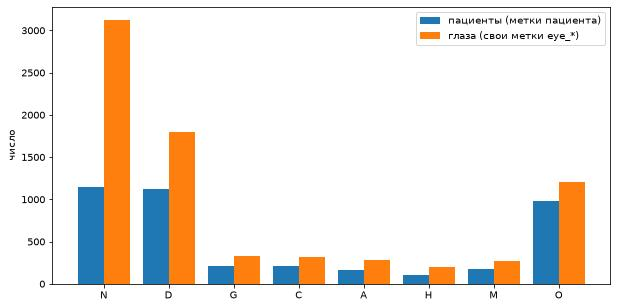

In [33]:
balance = pd.DataFrame(
    {
        "patients": patients[LABELS].sum(),
        "patients_%": (patients[LABELS].mean() * 100).round(1),
        "eyes": eyes[EYE_LABELS].sum().to_numpy(),
        "eyes_%": (eyes[EYE_LABELS].mean() * 100).round(1).to_numpy(),
    }
)
balance["max/class"] = (balance["patients"].max() / balance["patients"]).round(1)
print(balance)

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(LABELS))
ax.bar(x - 0.2, balance["patients"], 0.4, label="пациенты (метки пациента)")
ax.bar(x + 0.2, balance["eyes"], 0.4, label="глаза (свои метки eye_*)")
ax.set_xticks(x, LABELS)
ax.set_ylabel("число")
ax.legend()
save_figure(fig, "eda_class_balance");

**Результат:** у пациентов N 1140 (32.6%), D 1128 (32.2%), O 979 (28.0%), а дальше большой разрыв: G 215, C 212, M 174, A 164, H 103 (2.9%). Самый частый класс в 11 раз больше самого редкого (H). По собственным меткам глаз картина та же, но N больше (44.6% глаз против 32.6% пациентов): у многих больных пациентов один глаз здоров.

**Вывод и что делаем:**
- accuracy бесполезна, основная метрика - macro PR-AUC, смотреть её по каждому классу, особенно по редким (G, C, A, H, M);
- в лоссе - `pos_weight` = #neg / #pos (для H это ~35);
- разбиение на части - стратифицированное по меткам пациента;
- редких классов мало (H - 103 пациента на весь датасет), поэтому метрики по ним шумные: сравнивать модели по нескольким сидам.

### 1.3. Несколько болезней сразу

**Гипотеза:** у части пациентов несколько болезней, и некоторые классы часто идут вместе (например, гипертония и диабет).

**Зачем:** если метки связаны, модель может предсказывать одну болезнь по признакам другой; это важно и для интерпретации ошибок.

**Как проверяем:** число болезней у пациента и тепловая карта условных вероятностей P(класс в столбце | класс в строке).

diseases per patient: {0: 1140, 1: 1774, 2: 557, 3: 29}
patients with 2+ diseases: 586 (16.7%)
patients with D and O: 303, of them with a laser O keyword: 67 (22%)


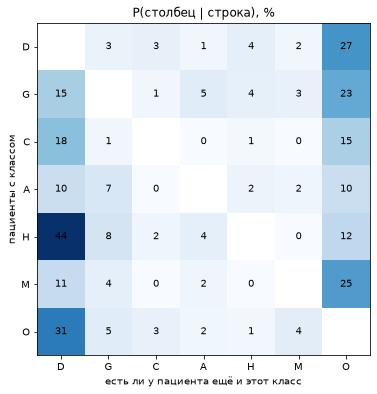

In [34]:
n_diseases = patients[DISEASES].sum(axis=1)
print("diseases per patient:", n_diseases.value_counts().sort_index().to_dict())
print(
    f"patients with 2+ diseases: {int((n_diseases >= 2).sum())} ({(n_diseases >= 2).mean():.1%})"
)
laser_kw = sorted(
    {
        kw
        for kws in eyes["keywords"]
        for kw in kws
        if "laser" in kw and keyword_to_label(kw) == "O"
    }
)
has_laser = eyes.groupby("patient_id")["keywords"].agg(
    lambda s: any(kw in laser_kw for kws in s for kw in kws)
)
d_and_o = patients.index[(patients["D"] == 1) & (patients["O"] == 1)]
print(
    f"patients with D and O: {len(d_and_o)}, of them with a laser O keyword: {int(has_laser[d_and_o].sum())} ({has_laser[d_and_o].mean():.0%})"
)
co = patients[DISEASES].T @ patients[DISEASES]
cond = co / np.diag(co)[:, None] * 100

fig, ax = plt.subplots(figsize=(7, 6))
ax.imshow(np.where(np.eye(len(DISEASES), dtype=bool), np.nan, cond), cmap="Blues")
for i in range(len(DISEASES)):
    for j in range(len(DISEASES)):
        if i != j:
            ax.text(
                j, i, f"{cond.iloc[i, j]:.0f}", ha="center", va="center", fontsize=10
            )
ax.set_xticks(range(len(DISEASES)), DISEASES)
ax.set_yticks(range(len(DISEASES)), DISEASES)
ax.set_xlabel("есть ли у пациента ещё и этот класс")
ax.set_ylabel("пациенты с классом")
ax.set_title("P(столбец | строка), %")
save_figure(fig, "eda_cooccurrence");

**Результат:** 1140 пациентов здоровы, 1774 с одной болезнью, 557 с двумя, 29 с тремя; 2+ болезни у 586 пациентов (16.7%). N по построению не сочетается ни с чем. Сильные связи на карте:
- D и O: у 27% пациентов с D есть O, у 31% с O есть D. Частично это объясняется лазерными следами после лечения ретинопатии: у 67 из 303 пациентов с D и O (22%) есть keyword O со словом laser. Остальные 78% сочетаний этим не объясняются;
- H и D: у 44% пациентов с H есть ещё и D;
- G: у 15% есть D, у 23% есть O.

Некоторые пары не встречаются вообще: C-A, C-M, M-H.

**Вывод и что делаем:** задача действительно multilabel (каждый шестой пациент с 2+ болезнями) - 8 независимых сигмоид и BCE, а не softmax. Связь H↔D означает, что модель может «угадывать» H по признакам диабетической ретинопатии: в анализе ошибок смотреть H отдельно у пациентов без D.

### 1.4. Больной и здоровый глаз

**Гипотеза:** многие болезни бывают только на одном глазу.

**Зачем:** если учить модель на отдельных снимках с метками пациента, здоровый глаз получит метку болезни.

**Как проверяем:** по собственным меткам глаз `eye_*`: у скольких пациентов болезнь на обоих глазах, у скольких на одном.

In [35]:
side = eyes.pivot(index="patient_id", columns="eye", values=EYE_LABELS).astype(bool)
one_eye = pd.DataFrame(
    {
        c: {
            "patients": int(patients[c].sum()),
            "both_eyes": int(
                (side[("eye_" + c, "left")] & side[("eye_" + c, "right")]).sum()
            ),
            "one_eye": int(
                (side[("eye_" + c, "left")] ^ side[("eye_" + c, "right")]).sum()
            ),
        }
        for c in DISEASES
    }
).T
one_eye["one_eye_%"] = (one_eye["one_eye"] / one_eye["patients"] * 100).round(1)
one_eye

,patients,both_eyes,one_eye,one_eye_%
D,1128,673,455,40.3
G,215,111,104,48.4
C,212,101,111,52.4
A,164,116,48,29.3
H,103,90,13,12.6
M,174,94,80,46.0
O,979,221,758,77.4


**Результат:** доля пациентов, у которых болезнь только на одном глазу: O 77.4%, C 52.4%, G 48.4%, M 46.0%, D 40.3%, A 29.3%, H 12.6%.

**Вывод и что делаем:** у заметной части больных пациентов болезнь видна только на одном глазу, поэтому для модели на один глаз берём собственные метки глаза `eye_*`, а не метки пациента. Метки пациента получаем агрегацией (`eyes_to_patient`: max по глазам для болезней, min для N).

### 1.5. Шум от копирования меток пациента на глаза

**Гипотеза:** если просто скопировать метки пациента на оба глаза, заметная часть глаз получит болезнь, которой у них нет по keywords.

**Зачем:** это шум в метках, который модель на один глаз будет учить.

**Как проверяем:** среди глаз, которые получили бы метку класса от пациента, доля глаз без этого класса по собственным keywords. Для N - доля глаз больных пациентов, которые сами здоровы.

In [36]:
noise = {}
for c in DISEASES:
    copied = eyes[eyes[c] == 1]
    wrong = int((copied["eye_" + c] == 0).sum())
    noise[c] = {
        "eyes_with_label": len(copied),
        "wrong": wrong,
        "wrong_%": round(wrong / len(copied) * 100, 1),
    }
sick = eyes[eyes["N"] == 0]
noise["N (eye healthy, patient not)"] = {
    "eyes_with_label": len(sick),
    "wrong": int(sick["eye_N"].sum()),
    "wrong_%": round(sick["eye_N"].mean() * 100, 1),
}
noise = pd.DataFrame(noise).T.astype({"eyes_with_label": int, "wrong": int})
print(noise)
copied_any = eyes[eyes[DISEASES].any(axis=1)]
extra = (
    copied_any[DISEASES].to_numpy()
    > copied_any[["eye_" + c for c in DISEASES]].to_numpy()
).any(axis=1)
print(
    f"eyes with at least one copied wrong disease label: {extra.sum()} of {len(copied_any)} eyes of sick patients ({extra.mean():.1%}), {extra.sum() / len(eyes):.1%} of all eyes"
)

                              eyes_with_label  wrong  wrong_%
D                                        2256    455     20.2
G                                         430    104     24.2
C                                         424    111     26.2
A                                         328     48     14.6
H                                         206     13      6.3
M                                         348     80     23.0
O                                        1958    758     38.7
N (eye healthy, patient not)             4720    845     17.9
eyes with at least one copied wrong disease label: 1492 of 4720 eyes of sick patients (31.6%), 21.3% of all eyes


**Результат:** при копировании меток ошибочная метка болезни у O 38.7% глаз, C 26.2%, G 24.2%, M 23.0%, D 20.2%, A 14.6%, H 6.3%. Хотя бы одну ложную болезнь получили бы 1492 глаза - 31.6% глаз больных пациентов (21.3% всех глаз). Ещё 845 здоровых по keywords глаз (17.9% глаз больных пациентов) потеряли бы метку N.

**Вывод и что делаем:** при копировании меток пациента у каждого третьего глаза больного пациента появляется хотя бы одна лишняя метка болезни. Поэтому модель на один глаз учим только на `eye_*` (`FundusDataset` по умолчанию берёт `EYE_LABELS`). Метки пациента используем для парной модели и для оценки на уровне пациента.

### 1.6. Класс O

**Гипотеза:** O («другое») - смесь десятков редких болезней, самый неоднородный класс.

**Зачем:** понять, из чего состоит O, - это нужно для анализа ошибок по этому классу.

**Как проверяем:** частоты keywords, которые дают O.

distinct keywords: 102, of them in O: 74
O eyes: 1200, top-10 keywords cover 77% of O keyword uses
patients with O as the only disease: 551 of 979
eyes with a laser keyword (fundus laser photocoagulation spots, laser spot, post laser photocoagulation, post retinal laser surgery): 125, of them with eye_D: 100 (80%)


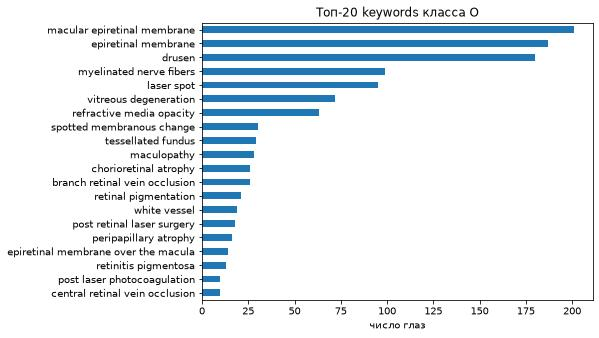

In [37]:
keyword_counts = Counter(kw for kws in eyes["keywords"] for kw in kws)
other = pd.Series(
    {kw: n for kw, n in keyword_counts.items() if keyword_to_label(kw) == "O"}
).sort_values(ascending=False)
print(f"distinct keywords: {len(keyword_counts)}, of them in O: {len(other)}")
print(
    f"O eyes: {int(eyes['eye_O'].sum())}, top-10 keywords cover {other.head(10).sum() / other.sum():.0%} of O keyword uses"
)
only_o = patients[(patients["O"] == 1) & (patients[DISEASES].sum(axis=1) == 1)]
print(
    f"patients with O as the only disease: {len(only_o)} of {int(patients['O'].sum())}"
)
laser_eyes = eyes[eyes["keywords"].map(lambda kws: any(kw in laser_kw for kw in kws))]
print(
    f"eyes with a laser keyword ({', '.join(laser_kw)}): {len(laser_eyes)}, of them with eye_D: {int(laser_eyes['eye_D'].sum())} ({laser_eyes['eye_D'].mean():.0%})"
)

fig, ax = plt.subplots(figsize=(7, 5))
other.head(20)[::-1].plot.barh(ax=ax)
ax.set_xlabel("число глаз")
ax.set_title("Топ-20 keywords класса O")
save_figure(fig, "eda_class_o_keywords");

**Результат:** из 102 разных keywords 74 попадают в O, топ-10 покрывают 77% упоминаний: эпиретинальная мембрана, друзы, миелиновые волокна, лазерные следы, деструкция стекловидного тела, помутнение сред. Дальше длинный хвост. У 551 из 979 пациентов с O это единственная болезнь. Из 125 глаз с лазерными keywords у 100 (80%) есть и `eye_D`.

**Вывод:** O - смесь десятков разных находок. То, что O учится как один класс, - постановка задачи, а не вывод этого анализа. В анализе ошибок по O стоит смотреть подтипы, например лазерные следы: 80% таких глаз одновременно с D.

### 1.7. Левый и правый глаз

**Гипотеза:** болезни встречаются на левом и правом глазу одинаково часто.

**Зачем:** если болезнь чаще бывает на одной стороне, сторона глаза сама несёт информацию о метке. Это важно для парной модели (вход «левый, правый») и для решения об отражении (5.1).

**Как проверяем:** у пациентов с болезнью только на одном глазу сравниваем «только левый» и «только правый». Тест знаков: z = (L - R) / √(L + R); порог значимости с поправкой Бонферрони на 7 двусторонних проверок - |z| > z(1 - 0.05/14).

In [38]:
z_crit = NormalDist().inv_cdf(1 - 0.05 / (2 * len(DISEASES)))
rows = {}
for c in DISEASES:
    left, right = side[("eye_" + c, "left")], side[("eye_" + c, "right")]
    only_l, only_r = int((left & ~right).sum()), int((right & ~left).sum())
    rows[c] = {
        "left": int(left.sum()),
        "right": int(right.sum()),
        "only_left": only_l,
        "only_right": only_r,
        "z": round((only_l - only_r) / np.sqrt(max(only_l + only_r, 1)), 2),
    }
left_right = pd.DataFrame(rows).T.astype(
    {"left": int, "right": int, "only_left": int, "only_right": int}
)
left_right["significant"] = left_right["z"].abs() > z_crit
print(
    f"Bonferroni threshold for {len(DISEASES)} two-sided tests at 0.05: |z| > {z_crit:.2f}"
)
left_right

Bonferroni threshold for 7 two-sided tests at 0.05: |z| > 2.69


,left,right,only_left,only_right,z,significant
D,888,913,215,240,-1.17,False
G,177,149,66,38,2.75,True
C,159,154,58,53,0.47,False
A,136,144,20,28,-1.15,False
H,96,97,6,7,-0.28,False
M,126,142,32,48,-1.79,False
O,577,623,356,402,-1.67,False


**Результат:** порог с поправкой Бонферрони |z| > 2.69. У G только левый глаз у 66 пациентов, только правый у 38 (z = 2.75) - разница формально значима. У остальных классов |z| ≤ 1.79, разница не значима.

**Вывод:** для G есть формально значимый перекос в сторону левого глаза, но эффект небольшой (66 против 38 пациентов) и чуть выше порога. Для остальных классов разницы между сторонами по этим данным нет.

## 2. Пациенты: возраст и пол

Возраст и пол известны при диагностике, их можно подавать в модель вместе со снимками.

### 2.1. Распределение возраста и выбросы

**Гипотеза:** возраст в основном 40-80 лет; есть неправдоподобные значения.

**Зачем:** выбросы в возрасте надо найти до того, как использовать возраст в анализе или в модели.

**Как проверяем:** гистограмма возраста по полу и boxplot; пациенты младше 10 лет.

median age 59, 5-95% range 38-75
median age by sex: {'Female': 60.0, 'Male': 57.0}
patients aged < 10: 16, ages {1: 16}, female 16, with M 13, IDs [1242, 1563, 1564, 1565, 1568, 1583, 1588, 1589, 1590, 1595, 1599, 1600, 1603, 1617, 1829, 2734]


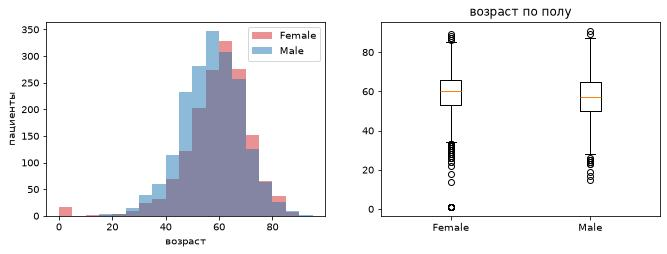

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
bins = np.arange(0, 100, 5)
for sex, color in [("Female", "tab:red"), ("Male", "tab:blue")]:
    axes[0].hist(
        patients.loc[patients["sex"] == sex, "age"],
        bins=bins,
        alpha=0.5,
        label=sex,
        color=color,
    )
axes[0].set_xlabel("возраст")
axes[0].set_ylabel("пациенты")
axes[0].legend()
axes[1].boxplot(
    [patients.loc[patients["sex"] == s, "age"] for s in ["Female", "Male"]],
    tick_labels=["Female", "Male"],
)
axes[1].set_title("возраст по полу")
save_figure(fig, "eda_age")

print(
    f"median age {patients['age'].median():.0f}, 5-95% range {patients['age'].quantile(0.05):.0f}-{patients['age'].quantile(0.95):.0f}"
)
print("median age by sex:", patients.groupby("sex")["age"].median().to_dict())
young = patients[patients["age"] < 10]
print(
    f"patients aged < 10: {len(young)}, ages {young['age'].value_counts().to_dict()}, "
    f"female {int((young['sex'] == 'Female').sum())}, with M {int(young['M'].sum())}, IDs {young.index.tolist()}"
)

**Результат:** медиана возраста 59 лет, 90% пациентов от 38 до 75 лет; медиана у женщин 60, у мужчин 57. У 16 пациентов записан возраст 1 год: все женщины, у 13 из них M, большая часть ID идёт подряд (1563-1617).

**Вывод:** распределение возраста правдоподобное, кроме 16 пациентов с возрастом 1 год. Предположение: это ошибка ввода, но по данным это не доказать. Что с ними делать (исключить, считать пропуском, оставить) - открытый вопрос. В статистиках ниже (2.2-2.4) они учитываются как есть.

### 2.2. Пол и классы

**Гипотеза:** некоторые болезни чаще у одного пола.

**Зачем:** пол известен при диагностике и может быть дополнительным признаком; если разница в частоте классов связана с возрастом, а не с полом, пол сам по себе ничего не добавляет.

**Как проверяем:** число пациентов каждого пола и доля каждого класса среди мужчин и женщин (с абсолютными числами); для C - доля по полу внутри возрастных групп.

In [40]:
by_sex = patients.groupby("sex")[LABELS].sum().T
by_sex.columns = [f"{s}_n" for s in by_sex.columns]
n_sex = patients["sex"].value_counts()
print("patients:", n_sex.to_dict())
for s in ["Female", "Male"]:
    by_sex[f"{s}_%"] = (by_sex[f"{s}_n"] / n_sex[s] * 100).round(1)
by_sex["F/M"] = (by_sex["Female_%"] / by_sex["Male_%"]).round(2)
print(by_sex)
women_10 = patients[(patients["sex"] == "Female") & (patients["age"] >= 10)]
men = patients[patients["sex"] == "Male"]
print(
    f"M without patients aged < 10: women {int(women_10['M'].sum())} of {len(women_10)} ({women_10['M'].mean():.1%}), men {int(men['M'].sum())} of {len(men)} ({men['M'].mean():.1%})"
)

age_band = pd.cut(
    patients["age"], [0, 49, 59, 69, 200], labels=["<50", "50-59", "60-69", "70+"]
)
c_rows = {}
for band, part in patients.groupby(age_band, observed=True):
    row = {}
    for s in ["Female", "Male"]:
        sub = part[part["sex"] == s]
        row[f"{s}_C"], row[f"{s}_patients"], row[f"{s}_%"] = (
            int(sub["C"].sum()),
            len(sub),
            round(sub["C"].mean() * 100, 1),
        )
    c_rows[band] = row
print("C by sex within age groups:")
pd.DataFrame(c_rows).T.astype(
    {"Female_C": int, "Female_patients": int, "Male_C": int, "Male_patients": int}
)

patients: {'Male': 1885, 'Female': 1615}
   Female_n  Male_n  Female_%  Male_%   F/M
N       497     643      30.8    34.1  0.90
D       498     630      30.8    33.4  0.92
G        90     125       5.6     6.6  0.85
C       123      89       7.6     4.7  1.62
A        76      88       4.7     4.7  1.00
H        38      65       2.4     3.4  0.71
M       110      64       6.8     3.4  2.00
O       480     499      29.7    26.5  1.12
M without patients aged < 10: women 97 of 1599 (6.1%), men 64 of 1885 (3.4%)
C by sex within age groups:


,Female_C,Female_patients,Female_%,Male_C,Male_patients,Male_%
<50,6,275,2.2,9,466,1.9
50-59,22,475,4.6,17,629,2.7
60-69,43,603,7.1,24,564,4.3
70+,52,262,19.8,39,226,17.3


**Результат:** мужчин 1885 (54%), женщин 1615 (46%). Почти все классы встречаются одинаково (отношение долей F/M 0.85-1.12), кроме:
- M - у женщин в 2 раза чаще (110 из 1615 = 6.8% против 64 из 1885 = 3.4%); 13 из 110 - пациентки с возрастом 1 год (2.1), без них 97 из 1599 = 6.1%, всё равно в 1.8 раза чаще;
- C - у женщин в 1.6 раза чаще (123 против 89). Внутри возрастных групп женщины тоже выше: 2.2% против 1.9% (<50), 4.6% против 2.7% (50-59), 7.1% против 4.3% (60-69), 19.8% против 17.3% (70+);
- H - у мужчин чаще (65 против 38, F/M 0.71).

**Вывод:** разницу по C возраст не объясняет: у женщин C чаще в каждой возрастной группе. Пол связан с частотой M, C и H, но насколько он полезен как признак модели, по этим таблицам сказать нельзя.

### 2.3. Возраст и классы

**Гипотеза:** болезни, связанные с возрастом (C, G, A), встречаются у старших пациентов чаще.

**Зачем:** если подавать возраст в модель, сильная связь возраста с классом даёт модели способ предсказывать класс без снимка.

**Как проверяем:** по возрастным группам - число пациентов с каждым классом и доля класса в группе (`_n` и `_%`), в последней строке - число пациентов в группе.

In [41]:
adults = patients
age_group = pd.cut(
    adults["age"],
    [0, 39, 49, 59, 69, 100],
    labels=["<40", "40-49", "50-59", "60-69", "70+"],
)
grouped = adults.groupby(age_group, observed=True)
group_counts = grouped[LABELS].sum().T
group_share = (grouped[LABELS].mean().T * 100).round(1)
by_age = pd.concat(
    {
        g: pd.DataFrame({"n": group_counts[g], "%": group_share[g]})
        for g in group_counts.columns
    },
    axis=1,
)
by_age.loc["patients", :] = [
    v for g in group_counts.columns for v in (grouped.size()[g], 100.0)
]
by_age.columns = [f"{g}_{k}" for g, k in by_age.columns]
by_age.astype({c: int for c in by_age.columns if c.endswith("_n")})

,<40_n,<40_%,40-49_n,40-49_%,50-59_n,50-59_%,60-69_n,60-69_%,70+_n,70+_%
N,76,37.3,201,37.4,385,34.9,351,30.1,127,26.0
D,63,30.9,197,36.7,411,37.2,368,31.5,89,18.2
G,11,5.4,20,3.7,42,3.8,80,6.9,62,12.7
C,6,2.9,9,1.7,39,3.5,67,5.7,91,18.6
A,5,2.5,16,3.0,51,4.6,63,5.4,29,5.9
H,4,2.0,18,3.4,38,3.4,42,3.6,1,0.2
M,20,9.8,12,2.2,46,4.2,53,4.5,43,8.8
O,43,21.1,126,23.5,285,25.8,376,32.2,149,30.5
patients,204,100.0,537,100.0,1104,100.0,1167,100.0,488,100.0


**Результат:**
- **Растут с возрастом:**
  - C - 1.7-3.5% до 60 лет, 5.7% в 60-69 и 18.6% (91 из 488) у 70+;
  - G - 3.7-6.9% до 70 лет и 12.7% у 70+;
  - A - с 2.5% до 5.9%;
  - O - с 21% до 30-32%.
- **M** растёт с 2.2% (40-49) до 8.8% (70+), но у моложе 40 тоже 9.8%: туда попадают пациентки с возрастом 1 год (2.1).
- **Падают:** N - с 37% до 26.0%; D держится на 31-37% до 69 лет, а у 70+ - 18.2%.
- **H у 70+:** 1 пациент из 488 против 2-4% в остальных группах. Это наблюдение, его стоит проверить, а не объяснять.
- **Размер групп:** больше всего пациентов 50-69 лет (1104 и 1167), моложе 40 - 204.

**Вывод:** сильнее всего с возрастом связаны C (в 70+ в 3-11 раз чаще, чем в группах до 70) и G (почти в 2 раза чаще, чем в 60-69). Если подавать возраст в модель, часть качества по C и G она сможет получить из одного возраста; чтобы это увидеть, качество надо сравнивать с моделью без возраста.

### 2.4. Число меток по возрасту

**Гипотеза:** у старших пациентов чаще несколько болезней.

**Как проверяем:** распределение числа болезней (0, 1, 2+) по возрастным группам.

In [42]:
labels_by_age = (
    pd.crosstab(
        age_group,
        adults[DISEASES].sum(axis=1).clip(upper=2).map({0: "0", 1: "1", 2: "2+"}),
        normalize="index",
    )
    * 100
)
labels_by_age["mean_diseases"] = grouped.apply(lambda g: g[DISEASES].sum(axis=1).mean())
labels_by_age.round(2)

col_0,0,1,2+,mean_diseases
age,,,,
<40,37.25,51.47,11.27,0.75
40-49,37.43,51.40,11.17,0.74
50-59,34.87,48.01,17.12,0.83
60-69,30.08,51.24,18.68,0.90
70+,26.02,54.30,19.67,0.95


**Результат:** среднее число болезней растёт с 0.74-0.75 (до 50 лет) до 0.95 (70+), доля пациентов с 2+ болезнями - с 11% до 19.7%.

**Вывод:** у старших пациентов болезней немного больше, но разница небольшая (0.74 против 0.95 болезни на пациента).

## 3. Качество снимков

### 3.1. Плохие снимки

**Гипотеза:** снимки с keywords качества (`low image quality`, `lens dust`, …) действительно хуже: темнее, менее резкие.

**Зачем:** по нечитаемому снимку модель не видит болезнь, а метка у глаза есть. Варианты: убрать из обучения, оставить или отсеивать отдельной проверкой качества перед моделью.

**Как проверяем:** число глаз с каждым keyword качества, доля здоровых, медианные яркость, контраст и резкость по сравнению с остальными; примеры снимков.

In [43]:
groups = {kw: has_keyword(kw) for kw in sorted(QUALITY_KEYWORDS)}
groups["без keywords качества"] = ~data["keywords"].map(
    lambda kws: bool(QUALITY_KEYWORDS & set(kws))
)
quality = pd.DataFrame(
    {
        name: {
            "eyes": int(m.sum()),
            "eye_N_%": data.loc[m, "eye_N"].mean() * 100,
            "only_quality_kw": int(
                (
                    m & data["keywords"].map(lambda kws: set(kws) <= QUALITY_KEYWORDS)
                ).sum()
            ),
            "gray_p50": data.loc[m, "gray_p50"].median(),
            "contrast": data.loc[m, "contrast"].median(),
            "sharpness": data.loc[m, "sharpness"].median(),
        }
        for name, m in groups.items()
    }
).T
quality.round(1)

,eyes,eye_N_%,only_quality_kw,gray_p50,contrast,sharpness
anterior segment image,2.0,100.0,2.0,116.0,53.9,89.1
image offset,1.0,100.0,1.0,64.0,14.9,20.9
lens dust,405.0,68.9,2.0,92.0,21.1,16.9
low image quality,21.0,95.2,20.0,85.0,21.7,15.1
no fundus image,1.0,100.0,1.0,78.0,15.0,8.0
optic disk photographically invisible,5.0,80.0,4.0,75.0,23.7,11.5
без keywords качества,6565.0,42.9,0.0,97.0,24.7,23.7


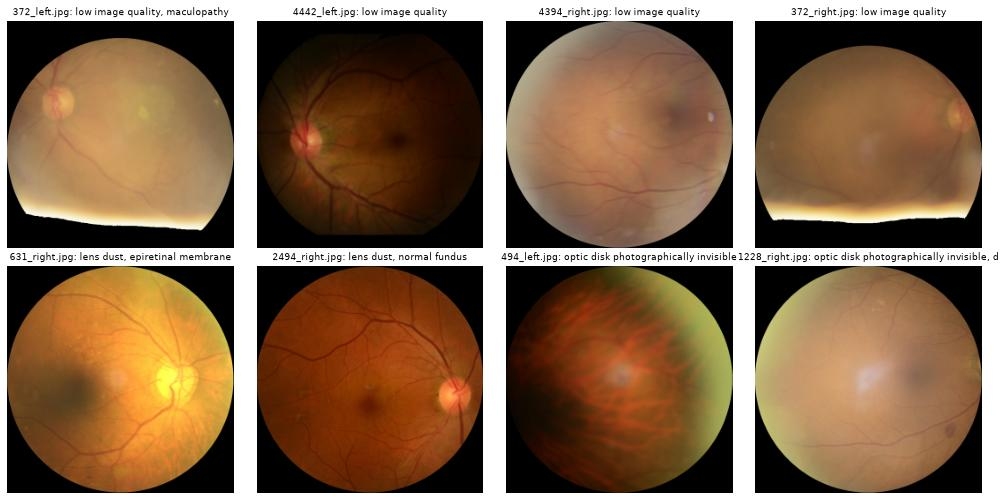

In [44]:
examples = (
    data.loc[has_keyword("low image quality"), "image"]
    .sample(4, random_state=SEED)
    .tolist()
    + data.loc[has_keyword("lens dust"), "image"].sample(2, random_state=SEED).tolist()
    + data.loc[has_keyword("optic disk photographically invisible"), "image"]
    .head(2)
    .tolist()
)
titles = [
    f"{i}: {', '.join(data.set_index('image').loc[i, 'keywords'])[:40]}"
    for i in examples
]
show_images([load_canonical(TRAIN_IMAGES_DIR / i) for i in examples], titles, ncols=4);

**Результат:**
- `lens dust` - 405 глаз, у 69% диагноз N, только у 2 глаз нет других keywords. Яркость почти как у остальных (92 против 97), а резкость 16.9 - близко к `low image quality` (15.1) и заметно ниже, чем у снимков без keywords качества (23.7). На показанных примерах снимки читаемые, пыль - отдельные мелкие пятна.
- `low image quality` - 21 глаз, у 20 нет ни одного диагноза, поэтому их метка глаза N=1. На примерах снимки размытые или с засветом, но частично читаемые. Резкость 15.1.
- `optic disk photographically invisible` - 5 глаз, резкость 11.5, на примерах диск действительно не виден.

**Вывод:** у снимков с `low image quality` и `optic disk photographically invisible` метка N=1 означает скорее «врач не смог оценить», чем «здоров». Снимки с `lens dust` по резкости ближе к плохим, хотя на примерах выглядят читаемыми.

**Открытый вопрос:**
- что делать с ~30 нечитаемыми глазами (`low image quality`, `optic disk photographically invisible`, `no fundus image`, `anterior segment image`): исключить из лосса модели на один глаз (пациент остаётся, метку даёт второй глаз), оставить или отсеивать отдельной проверкой качества перед моделью (например, по `sharpness` и `gray_p50`);
- оставлять ли 405 глаз с `lens dust` как обычные снимки.

### 3.2. Ошибки в снимках

**Гипотеза:** среди 7000 снимков есть не снимки глазного дна или испорченные.

**Зачем:** такие ошибки надо найти до обучения.

**Как проверяем:**
- снимки с keywords `anterior segment image`, `no fundus image`, `image offset` (показаны все);
- маленькие снимки (ширина < 500 px);
- самые тёмные и самые светлые (медианная яркость ниже p1 или выше p99 по всем снимкам) и с самой маленькой долей глазного дна в кадре (ниже p1) - с числом снимков, числом и долей C.

Для категорий по порогам показываем по 8 случайных снимков. Вердикты по ним - на просмотренных примерах, а не проверка всех снимков категории.

In [45]:
dark_t, bright_t, frac_t = (
    np.percentile(data["gray_p50"], 1),
    np.percentile(data["gray_p50"], 99),
    np.percentile(data["fundus_frac"], 1),
)
print(
    f"thresholds: brightness p1 = {dark_t:.0f}, p99 = {bright_t:.0f}; fundus share p1 = {frac_t:.2f}"
)
is_c = data["eye_C"] == 1
categories = [
    (
        "keyword anterior segment image",
        has_keyword("anterior segment image"),
        "не глазное дно",
        "открытый вопрос (3.1)",
    ),
    (
        "keyword no fundus image",
        has_keyword("no fundus image"),
        "ошибка в keyword",
        "оставить, keyword не учитывать",
    ),
    (
        "keyword image offset",
        has_keyword("image offset"),
        "нормальный снимок",
        "оставить",
    ),
    (
        "ширина < 500 px",
        data["width"] < 500,
        "нормальный снимок",
        "оставить (низкое разрешение)",
    ),
    (
        f"яркость < p1 ({dark_t:.0f})",
        data["gray_p50"] < dark_t,
        "нормальный снимок",
        "оставить (тёмная экспозиция)",
    ),
    (
        f"яркость > p99 ({bright_t:.0f})",
        data["gray_p50"] > bright_t,
        "признак болезни (C) или нормальный снимок",
        "оставить",
    ),
    (
        f"доля глазного дна < p1 ({frac_t:.2f})",
        data["fundus_frac"] < frac_t,
        "нормальный снимок",
        "оставить (маленький круг в широком кадре)",
    ),
]
summary_table = pd.DataFrame(
    [
        {
            "категория": name,
            "снимков": int(m.sum()),
            "из них C": int((m & is_c).sum()),
            "доля C, %": round((m & is_c).sum() / m.sum() * 100, 1),
            "примеры": ", ".join(
                data.loc[m, "image"].sample(min(2, int(m.sum())), random_state=SEED)
            ),
            "вердикт": verdict,
            "что делаем": action,
        }
        for name, m, verdict, action in categories
    ]
)
print(f"share of C among all eyes: {is_c.mean():.1%}")
summary_table

thresholds: brightness p1 = 34, p99 = 181; fundus share p1 = 0.41
share of C among all eyes: 4.5%


,категория,снимков,из них C,"доля C, %",примеры,вердикт,что делаем
0,keyword anterior segment image,2,0,0.0,"1710_right.jpg, 1706_left.jpg",не глазное дно,открытый вопрос (3.1)
1,keyword no fundus image,1,0,0.0,4580_left.jpg,ошибка в keyword,"оставить, keyword не учитывать"
2,keyword image offset,1,0,0.0,1243_left.jpg,нормальный снимок,оставить
3,ширина < 500 px,20,0,0.0,"3_left.jpg, 3155_right.jpg",нормальный снимок,оставить (низкое разрешение)
4,яркость < p1 (34),58,6,10.3,"59_left.jpg, 1222_right.jpg",нормальный снимок,оставить (тёмная экспозиция)
5,яркость > p99 (181),68,19,27.9,"2394_left.jpg, 1126_right.jpg",признак болезни (C) или нормальный снимок,оставить
6,доля глазного дна < p1 (0.41),70,4,5.7,"709_right.jpg, 4_left.jpg",нормальный снимок,оставить (маленький круг в широком кадре)


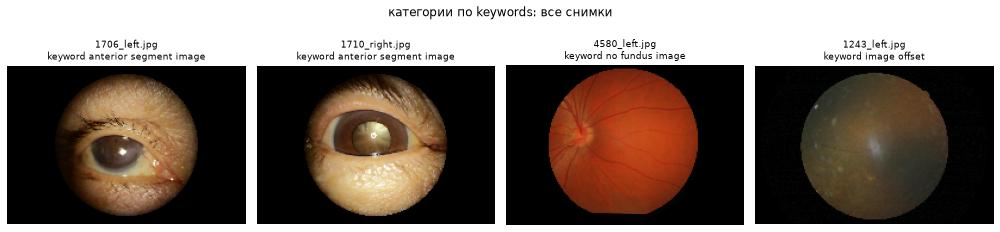

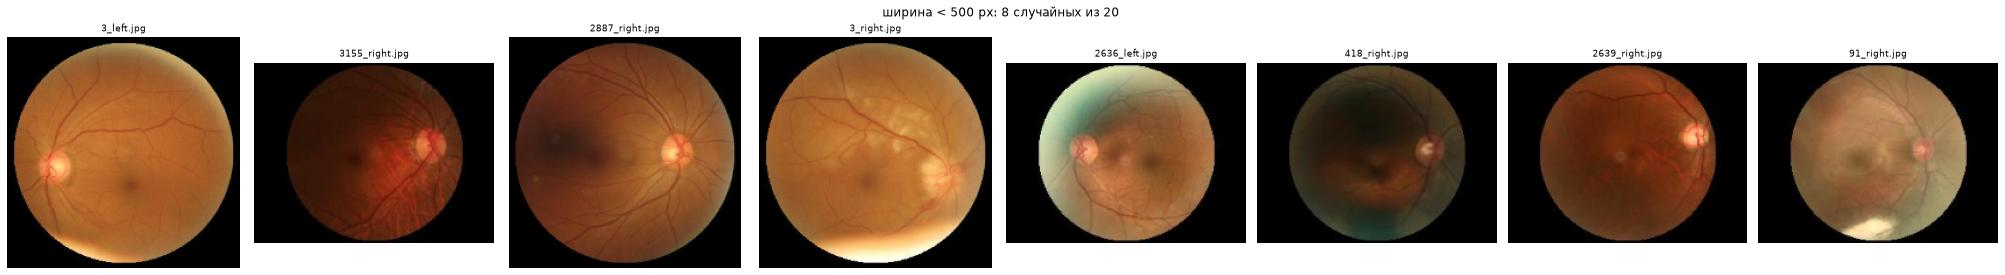

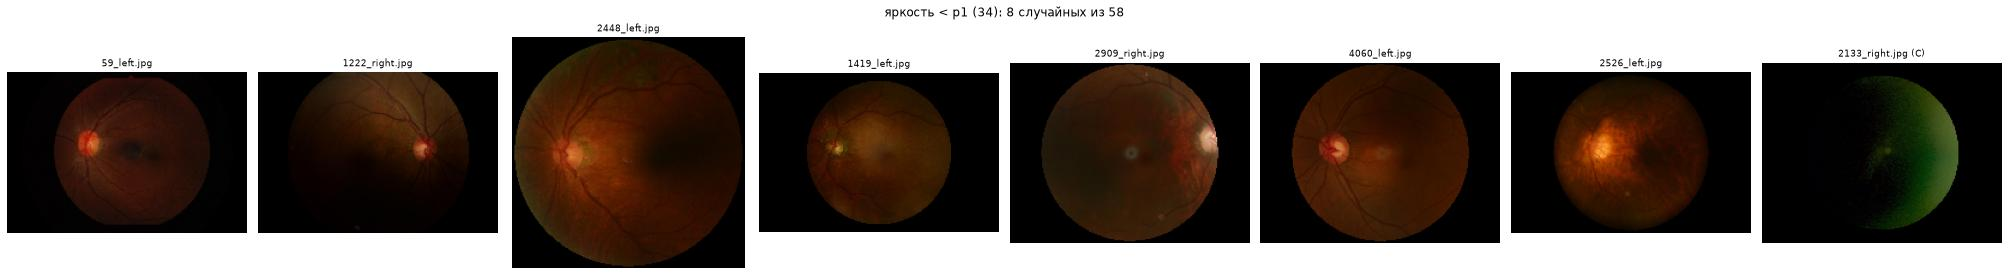

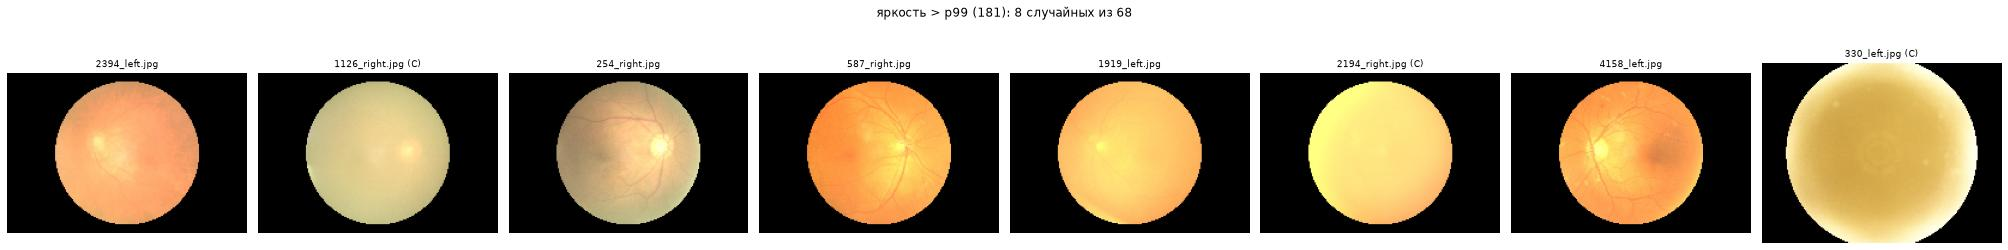

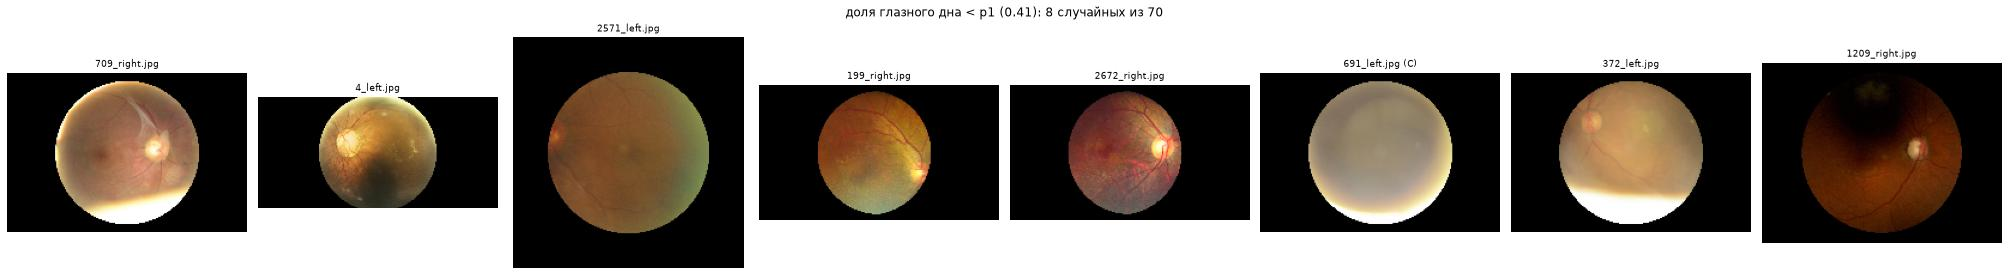

In [46]:
eye_c = data.set_index("image")["eye_C"]
keyword_items = [
    (i, name) for name, m, _, _ in categories[:3] for i in data.loc[m, "image"]
]
fig = show_images(
    [small(i, 200) for i, _ in keyword_items],
    [f"{i}\n{n}" for i, n in keyword_items],
    ncols=4,
)
fig.suptitle("категории по keywords: все снимки", y=1.05)
for name, m, _, _ in categories[3:]:
    picked = data.loc[m, "image"].sample(8, random_state=SEED).tolist()
    fig = show_images(
        [small(i, 200) for i in picked],
        [f"{i}{' (C)' if eye_c[i] else ''}" for i in picked],
        ncols=8,
    )
    fig.suptitle(f"{name}: 8 случайных из {int(m.sum())}", y=1.08)

**Результат и вывод по вердиктам:**
- **Не глазное дно:** 2 снимка (`1706_left`, `1710_right`) - фото переднего отдела глаза. Что с ними делать - открытый вопрос в 3.1.
- **Ошибка в keyword:** `4580_left` (`no fundus image`) - на самом деле обычный снимок глазного дна. Снимок оставляем, keyword не учитываем.
- **Нормальный снимок (на просмотренных примерах):**
  - `image offset` - смещённый, но читаемый;
  - маленькие (20 снимков 250×188 и 320×316) - все 8 просмотренных читаемы;
  - тёмные (58 ниже p1, из них C 6, 10%) - 7 из 8 просмотренных читаемы (диск и сосуды видны), нечитаем снимок катаракты `2133_right`;
  - с маленькой долей глазного дна (70 ниже p1, из них C 4) - маленький круг в широком кадре, часто с засветом снизу; на просмотренных примерах читаемы.
- **Яркие снимки (68 выше p99):** 19 из них с C (27.9% против 4.5% среди всех глаз). На просмотренных примерах снимки с C - засвет и мутность без деталей, остальные - яркие, но с видимыми сосудами.

Маленькие снимки и форма кадра - признаки камеры (раздел 4).

### 3.3. Дубликаты

**Гипотеза:** одни и те же снимки встречаются у разных пациентов.

**Зачем:** если копии одного глаза попадут в разные части разбиения, качество модели будет завышено.

**Как проверяем:**
1. **Точные копии** - `md5` файлов.
2. **Кандидаты** - пары снимков разных пациентов (все 8000, включая Testing Images) с расстоянием между `hash16` (снимок 16×16 в оттенках серого после канонической обрезки, RMS-разница) ниже порога. Порог выбираем по распределению расстояния до ближайшего снимка другого пациента.
3. **Подтверждение по пикселям.** Для каждой пары кандидатов:
   - декодируем оригиналы в полном разрешении (при разных размерах приводим к меньшему), считаем среднюю абсолютную разницу (MAD) и PSNR, сравниваем размеры и размер файлов;
   - MAD и PSNR по всему кадру сильно зависят от чёрного фона, поэтому решающая мера - корреляция мелких деталей `detail_r`: полосовой фильтр (разность гауссиан σ=1.5 и σ=6, сосуды и мелкие детали) зелёного канала на канонической версии 512×512, только внутренняя часть круга, максимум по сдвигам до ±6 px. У одного и того же глаза сосуды совпадают, у разных - нет.
   - Для сравнения те же меры для 100 типичных пар: разные пациенты, та же камера (размер снимка) и та же сторона глаза.
4. Подтверждённые пары показываем в оригинале рядом, с ID, метками, возрастом и полом обоих пациентов.

files with the same md5: 0
nearest image of another patient: p1 4.5, p5 5.6, median 8.9
threshold 5.0: 1.9% of images have a neighbour closer than that
candidate pairs: 102


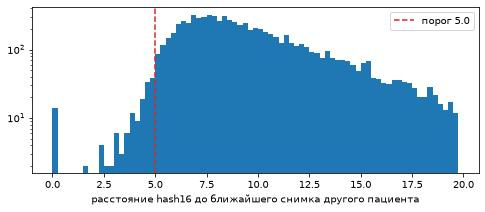

In [47]:
print("files with the same md5:", int(stats["md5"].duplicated().sum()))
hashes = np.stack(
    [np.frombuffer(bytes.fromhex(h), np.uint8) for h in stats["hash16"]]
).astype(np.float32)
sq = (hashes**2).sum(axis=1)
dist = np.sqrt(
    np.maximum(sq[:, None] + sq[None, :] - 2 * hashes @ hashes.T, 0) / hashes.shape[1]
)
owner = (stats["image_set"] + "_" + stats["patient_id"].astype(str)).to_numpy()
dist[owner[:, None] == owner[None, :]] = np.inf
nearest = dist.min(axis=1)
HASH_THRESHOLD = 5.0
print(
    f"nearest image of another patient: p1 {np.percentile(nearest, 1):.1f}, p5 {np.percentile(nearest, 5):.1f}, median {np.median(nearest):.1f}"
)
print(
    f"threshold {HASH_THRESHOLD}: {(nearest < HASH_THRESHOLD).mean():.1%} of images have a neighbour closer than that"
)
fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(nearest[np.isfinite(nearest)], bins=np.arange(0, 20, 0.25))
ax.axvline(
    HASH_THRESHOLD, color="tab:red", linestyle="--", label=f"порог {HASH_THRESHOLD}"
)
ax.set_yscale("log")
ax.set_xlabel("расстояние hash16 до ближайшего снимка другого пациента")
ax.legend()
save_figure(fig, "eda_duplicates_hash")
first, second = np.triu_indices(len(stats), 1)
close = dist[first, second] < HASH_THRESHOLD
candidates = pd.DataFrame(
    {
        "a": first[close],
        "b": second[close],
        "hash_dist": dist[first, second][close].round(2),
    }
)
candidates = candidates.sort_values("hash_dist", ignore_index=True)
print("candidate pairs:", len(candidates))

In [48]:
def raw_diff(a: pd.Series, b: pd.Series) -> tuple[float, float]:
    img_a, img_b = (
        load_image(FOLDERS[a["image_set"]] / a["image"]),
        load_image(FOLDERS[b["image_set"]] / b["image"]),
    )
    h, w = min(img_a.shape[0], img_b.shape[0]), min(img_a.shape[1], img_b.shape[1])
    img_a, img_b = (
        cv2.resize(x, (w, h), interpolation=cv2.INTER_AREA)
        if x.shape[:2] != (h, w)
        else x
        for x in (img_a, img_b)
    )
    diff = np.abs(img_a.astype(np.float32) - img_b.astype(np.float32))
    return float(diff.mean()), float(
        10 * np.log10(255**2 / max((diff**2).mean(), 1e-10))
    )


def details(row: pd.Series) -> tuple[np.ndarray, np.ndarray]:
    img = load_canonical(FOLDERS[row["image_set"]] / row["image"], 512)
    green = img[..., 1].astype(np.float32)
    band = cv2.GaussianBlur(green, (0, 0), 1.5) - cv2.GaussianBlur(green, (0, 0), 6)
    radius = cv2.distanceTransform(fundus_mask(img).astype(np.uint8), cv2.DIST_L2, 5)
    return band, radius > 0.15 * radius.max()


def detail_corr(a: pd.Series, b: pd.Series, max_shift: int = 6) -> float:
    (band_a, mask_a), (band_b, mask_b) = details(a), details(b)
    best = -1.0
    for dy in range(-max_shift, max_shift + 1):
        for dx in range(-max_shift, max_shift + 1):
            shifted = np.roll(band_b, (dy, dx), (0, 1))
            m = mask_a & np.roll(mask_b, (dy, dx), (0, 1))
            x, y = band_a[m] - band_a[m].mean(), shifted[m] - shifted[m].mean()
            best = max(best, float(x @ y / np.sqrt((x @ x) * (y @ y))))
    return best


def compare(pair: tuple[int, int]) -> dict:
    a, b = stats.iloc[pair[0]], stats.iloc[pair[1]]
    mad, psnr = raw_diff(a, b)
    return {"mad": mad, "psnr": psnr, "detail_r": detail_corr(a, b)}


pair_rng = np.random.default_rng(SEED)
train_idx = np.flatnonzero(stats["image_set"] == "train")
typical_pairs = []
while len(typical_pairs) < 100:
    a = pair_rng.choice(train_idx)
    same = train_idx[
        (stats["size"].iloc[train_idx] == stats["size"].iloc[a]).to_numpy()
        & (stats["eye"].iloc[train_idx] == stats["eye"].iloc[a]).to_numpy()
        & (
            stats["patient_id"].iloc[train_idx] != stats["patient_id"].iloc[a]
        ).to_numpy()
    ]
    if len(same):
        typical_pairs.append((a, pair_rng.choice(same)))
with ThreadPoolExecutor(8) as pool:
    typical = pd.DataFrame(list(pool.map(compare, typical_pairs)))
    measured = pd.DataFrame(
        list(pool.map(compare, zip(candidates["a"], candidates["b"])))
    )
candidates = candidates.join(measured)
R_THRESHOLD = 0.5
candidates["confirmed"] = candidates["detail_r"] > R_THRESHOLD
print(
    f"typical pairs (different patients, same camera and eye side, n={len(typical)}):"
)
print(typical.describe(percentiles=[0.5, 0.99]).loc[["50%", "99%", "max"]].round(2))
print(f"confirmation threshold: detail_r > {R_THRESHOLD}")
print(
    candidates.groupby("confirmed")[["hash_dist", "mad", "psnr", "detail_r"]]
    .median()
    .round(2)
)
borderline = candidates[(candidates["detail_r"] > 0.2) & ~candidates["confirmed"]]
for r in borderline.itertuples():
    print(
        f"borderline, not confirmed: {stats['image'].iloc[r.a]} / {stats['image'].iloc[r.b]}, hash {r.hash_dist:.2f}, detail_r {r.detail_r:.2f}"
    )

typical pairs (different patients, same camera and eye side, n=100):
       mad   psnr  detail_r
50%  18.15  18.78      0.05
99%  65.60  26.68      0.16
max  98.48  26.97      0.32
confirmation threshold: detail_r > 0.5
           hash_dist   mad   psnr  detail_r
confirmed                                  
False           4.62  4.45  29.54      0.08
True            0.87  0.73  54.18      0.99
borderline, not confirmed: 568_left.jpg / 819_left.jpg, hash 4.02, detail_r 0.20
borderline, not confirmed: 3012_left.jpg / 3270_left.jpg, hash 4.37, detail_r 0.22
borderline, not confirmed: 1109_right.jpg / 1166_right.jpg, hash 4.45, detail_r 0.31
borderline, not confirmed: 26_left.jpg / 3288_left.jpg, hash 4.99, detail_r 0.24


In [49]:
def describe_image(row: pd.Series) -> str:
    if row["image_set"] == "test":
        return f"Testing/{row['image']} (без меток)"
    p = patients.loc[row["patient_id"]]
    labels = ",".join(c for c in LABELS if p[c])
    return f"{row['image']}: ID {row['patient_id']}, {labels}, {p['age']} {p['sex']}"


def kind(r: pd.Series) -> str:
    if r["mad"] < 0.5:
        return "одинаковые пиксели"
    if r["detail_r"] > 0.8:
        return "тот же снимок, пересохранён"
    return "тот же глаз, другой снимок"


dups = candidates[candidates["confirmed"]].copy()
dups["kind"] = dups.apply(kind, axis=1)
a_rows, b_rows = (
    stats.iloc[dups["a"]].reset_index(drop=True),
    stats.iloc[dups["b"]].reset_index(drop=True),
)
dup_table = pd.DataFrame(
    {
        "a": a_rows.apply(describe_image, axis=1),
        "b": b_rows.apply(describe_image, axis=1),
        "size": a_rows["size"] + " / " + b_rows["size"],
        "file_kb": a_rows["file_kb"].round().astype(int).astype(str)
        + " / "
        + b_rows["file_kb"].round().astype(int).astype(str),
        "hash_dist": dups["hash_dist"].to_numpy(),
        "mad": dups["mad"].round(2).to_numpy(),
        "psnr": dups["psnr"].round(1).to_numpy(),
        "detail_r": dups["detail_r"].round(3).to_numpy(),
        "kind": dups["kind"].to_numpy(),
    }
)
print(dup_table["kind"].value_counts().to_dict())
dup_table

{'одинаковые пиксели': 7, 'тот же снимок, пересохранён': 6, 'тот же глаз, другой снимок': 1}


,a,b,size,file_kb,hash_dist,mad,psnr,detail_r,kind
0,Testing/2276_right.jpg (без меток),Testing/2277_right.jpg (без меток),2304x1728 / 2304x1728,94 / 94,0.00,0.00,69.8,1.000,одинаковые пиксели
1,"352_right.jpg: ID 352, O, 70 Male","973_right.jpg: ID 973, O, 70 Male",2304x1728 / 2304x1728,129 / 129,0.00,0.00,76.5,1.000,одинаковые пиксели
2,"352_left.jpg: ID 352, O, 70 Male","973_left.jpg: ID 973, O, 70 Male",2304x1728 / 2304x1728,108 / 108,0.00,0.00,74.4,1.000,одинаковые пиксели
3,Testing/2276_left.jpg (без меток),Testing/2277_left.jpg (без меток),2304x1728 / 2304x1728,98 / 98,0.00,0.00,70.4,1.000,одинаковые пиксели
4,"2487_right.jpg: ID 2487, N, 63 Male","3185_right.jpg: ID 3185, N, 63 Male",2304x1728 / 2304x1728,123 / 123,0.00,0.00,70.7,1.000,одинаковые пиксели
5,"2487_left.jpg: ID 2487, N, 63 Male","3185_left.jpg: ID 3185, N, 63 Male",2304x1728 / 2304x1728,127 / 127,0.00,0.00,78.4,1.000,одинаковые пиксели
6,"1864_left.jpg: ID 1864, G,O, 65 Male","1865_left.jpg: ID 1865, G,O, 65 Male",2304x1728 / 2304x1728,140 / 140,0.00,0.00,86.2,1.000,одинаковые пиксели
7,"398_right.jpg: ID 398, D,O, 59 Female","668_right.jpg: ID 668, D,O, 67 Male",1936x1296 / 1936x1296,79 / 79,1.74,1.46,38.6,0.955,"тот же снимок, пересохранён"
8,"398_left.jpg: ID 398, D,O, 59 Female","668_left.jpg: ID 668, D,O, 67 Male",1936x1296 / 1936x1296,85 / 85,2.32,2.17,34.5,0.981,"тот же снимок, пересохранён"
9,"4485_right.jpg: ID 4485, D,O, 49 Female",Testing/4646_right.jpg (без меток),1936x1296 / 1936x1296,80 / 81,2.37,1.96,30.5,0.808,"тот же снимок, пересохранён"


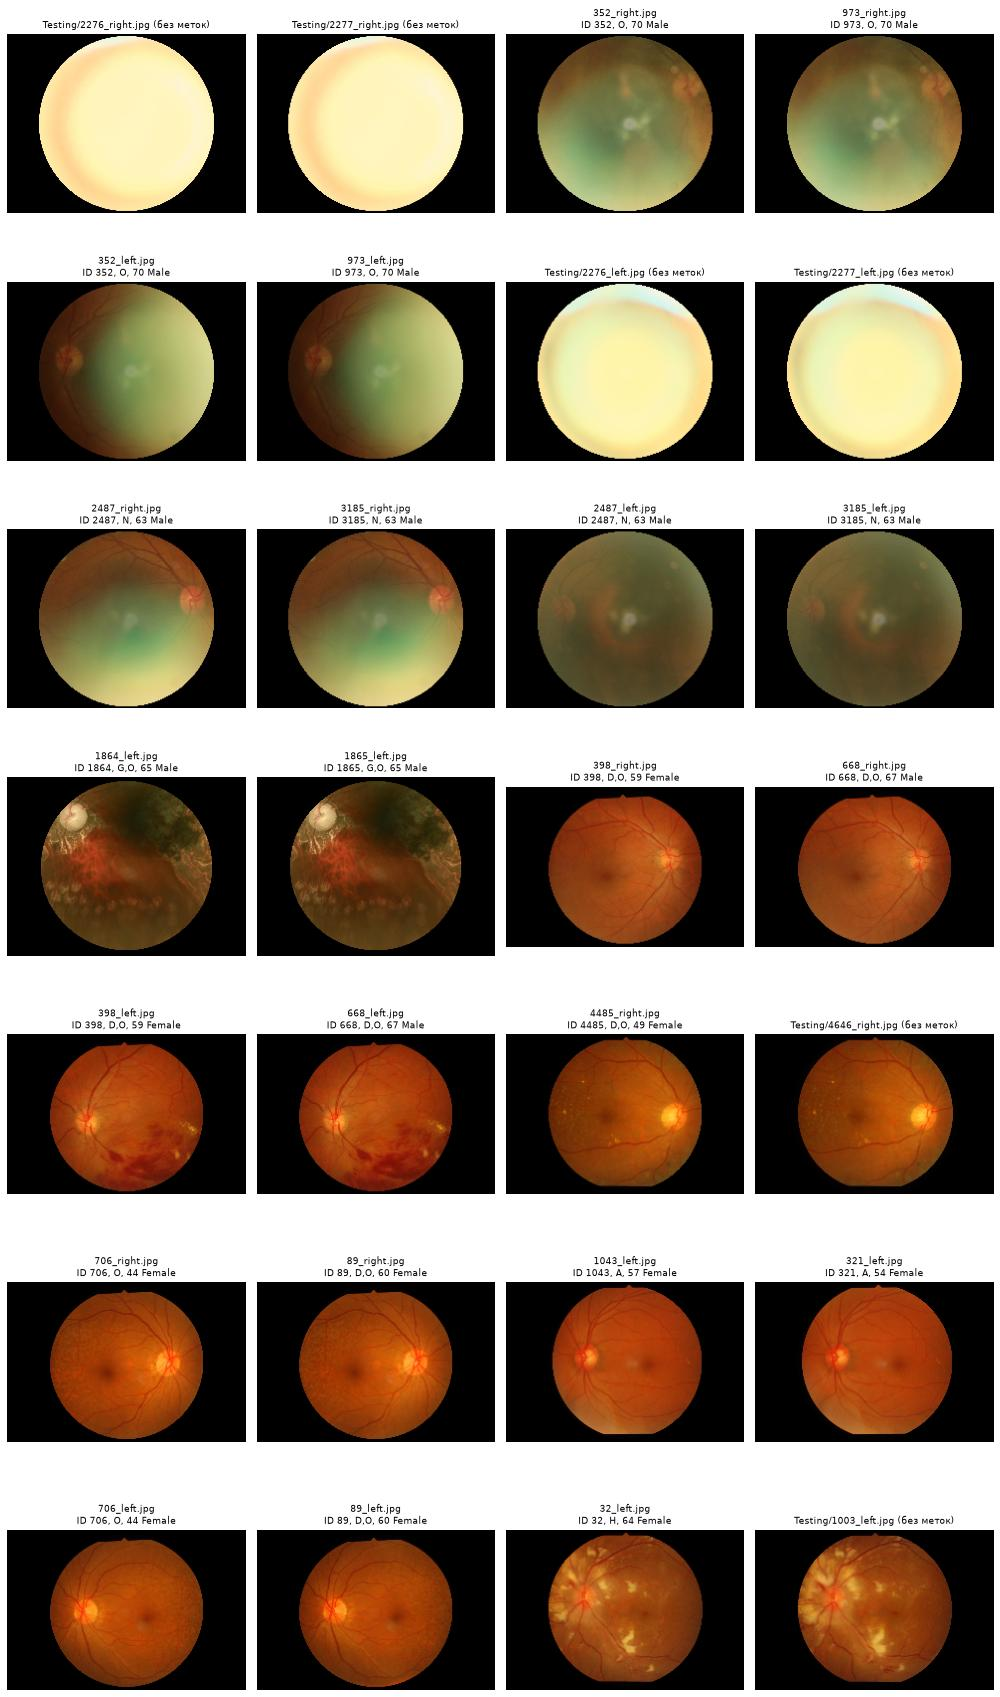

In [50]:
images, titles = [], []
for a, b in zip(a_rows.itertuples(), b_rows.itertuples()):
    for r in (a, b):
        images.append(small(r.image, 240, FOLDERS[r.image_set]))
        titles.append(describe_image(pd.Series(r._asdict())).replace(": ", "\n", 1))
show_images(images, titles, ncols=4);

**Результат:**
- **Точных копий нет:** `md5` всех 8000 файлов разные, даже у тех пар, которые совпадают по пикселям (файлы пересохранены).
- **Кандидаты.** Расстояние до ближайшего снимка другого пациента обычно около 9, 1-й перцентиль 4.5. Порог 5.0 (у 1.9% снимков есть сосед ближе) даёт 102 пары-кандидата.
- **Типичные пары** (разные пациенты, та же камера): MAD ~18, PSNR ~19 (максимум 27), `detail_r` около 0.05 (p99 0.16). Максимум 0.32 - у пары разных глаз с одинаковыми пятнами пыли на линзе камеры. Порог подтверждения `detail_r` > 0.5 выше всех типичных пар.
- **Подтверждено 14 пар** (медиана `detail_r` 0.99, MAD 0.7, PSNR 54); у остальных 88 кандидатов `detail_r` около 0.08, как у типичных пар:
  - **7 пар с одинаковыми пикселями** (MAD 0, те же размер и размер файла): оба глаза пациентов 352 и 973, 2487 и 3185, левый глаз 1864 и 1865, оба глаза 2276 и 2277 в Testing Images;
  - **6 пар - тот же снимок, пересохранённый** (`detail_r` 0.81-0.98, размер тот же, файл отличается на 0-2 KB): оба глаза 398 и 668, оба глаза 706 и 89, левый глаз 1043 и 321, правый глаз 4485 и `4646_right` из Testing Images;
  - **1 пара - тот же глаз, другой снимок** (`detail_r` 0.57): `32_left` и `1003_left` из Testing Images; очаги на снимках немного отличаются, похоже на повторный визит.
- **Пограничные случаи.** 4 пары с `detail_r` 0.20-0.31 (ниже порога, в диапазоне типичных пар до 0.32). Одна из них, `1109_right` / `1166_right`, на глаз похожа на тот же глаз со сдвигом, но по пикселям это не отличить от случайного совпадения.
- **Метаданные копий.** У 352/973, 2487/3185 и 1864/1865 совпадают возраст, пол и метки. У 398 (59 лет, женщина) и 668 (67 лет, мужчина) метки те же, а возраст и пол разные. У 706 (O, 44 года) и 89 (D+O, 60 лет) различаются и метки, и возраст. У 1043 и 321 возраст 57 и 54.

**Вывод и что делаем:**
- Это снимки одного и того же глаза под разными ID: 6 пар пациентов в Training Images, 2 пары между Training и Testing Images и 1 пара внутри Testing Images. 13 пар - один и тот же снимок; если у таких копий разные возраст, пол или метки (398/668, 706/89), это ошибка в данных. Пара `32_left` / `1003_left` - другой снимок того же глаза, возможно повторный визит, а не ошибка.
- При разбиении по пациентам такие пары нужно объединять в одну группу, чтобы копии всегда попадали в одну часть.
- Расхождения в метках (706/89) - кандидаты на проверку разметки.

## 4. Камеры и shortcut learning

### 4.1. Камера подсказывает ответ

**Гипотеза:** размер снимка и цвет фона (то есть камера и клиника) связаны с классом.

**Зачем:** модель может выучить камеру вместо болезни.

**Как проверяем:** доли собственных меток глаз по группам камер; отношение доли класса в группе к доле по всем глазам; метки снимков с белым фоном.

distinct sizes: 101
background: {'black': 6985, 'white': 15}
           eyes     N     D    G    C    A    H    M     O
camera                                                    
2592x1728  2146  36.9  36.7  2.2  3.2  4.8  3.6  2.0  20.6
2048x1536   524  49.4  22.9  4.0  3.8  1.9  1.3  5.0  17.6
2304x1728   424  60.8   9.7  7.5  4.2  3.1  1.2  3.8  12.7
1956x1934   390  49.7  22.3  2.6  7.4  2.1  0.5  6.4  12.8
2736x1824   344  43.3  18.6  7.8  8.4  3.8  1.2  6.4  16.3
1936x1296   284  46.5  20.8  2.8  0.7  6.0  2.8  4.9  23.9
other      2888  46.5  22.3  6.2  5.1  4.1  3.1  4.3  15.2
white background eyes, eye labels: {'eye_N': 3, 'eye_D': 0, 'eye_G': 0, 'eye_C': 12, 'eye_A': 0, 'eye_H': 0, 'eye_M': 0, 'eye_O': 0}


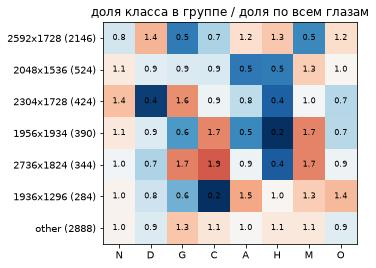

In [51]:
print("distinct sizes:", data["size"].nunique())
print("background:", data["background"].value_counts().to_dict())
cam = data.groupby("camera")[EYE_LABELS].mean() * 100
cam.columns = LABELS
cam.insert(0, "eyes", data.groupby("camera").size())
cam = cam.loc[CAMERAS]
print(cam.round(1))
print(
    "white background eyes, eye labels:",
    data.loc[data["background"] == "white", EYE_LABELS].sum().to_dict(),
)

ratio = cam[LABELS] / (data[EYE_LABELS].mean().to_numpy() * 100)
fig, ax = plt.subplots(figsize=(7, 4))
ax.imshow(np.log2(ratio), cmap="RdBu_r", vmin=-1.5, vmax=1.5)
for r in range(len(ratio)):
    for c in range(len(LABELS)):
        ax.text(c, r, f"{ratio.iloc[r, c]:.1f}", ha="center", va="center", fontsize=8)
ax.set_xticks(range(len(LABELS)), LABELS)
ax.set_yticks(
    range(len(ratio)), [f"{s} ({n})" for s, n in zip(ratio.index, cam["eyes"])]
)
ax.set_title("доля класса в группе / доля по всем глазам")
save_figure(fig, "eda_camera_vs_class");

**Результат:** 101 разный размер снимков. Классы распределены по камерам заметно по-разному:
- 2592×1728 (2146 глаз, 31%) - D 36.7% против 22% в остальных, N всего 36.9%;
- 2304×1728 - N 60.8%, D 9.7%, G 7.5%;
- 2736×1824 - C 8.4%, G 7.8%;
- 1956×1934 - C 7.4%, H 0.5%;
- 1936×1296 - C 0.7%.

Белый фон у 15 снимков одной камеры (2464×1632), из них 12 с C.

**Вывод:** камера - потенциальный shortcut: распределение классов зависит от камеры, особенно для D. Поэтому:
- вход модели канонический (`crop_to_fundus` с чёрным фоном → квадрат → resize), так что размер кадра и цвет фона напрямую модели не видны; узнаёт ли модель камеру после этого, проверяем в 4.2;
- качество моделей дополнительно смотрим по группам камер: если качество D держится только на 2592×1728, модель учит камеру.

### 4.2. Эмбеддинги ResNet18: камера или болезнь?

**Гипотеза:** замороженные ImageNet-эмбеддинги (`data/processed/embeddings/resnet18/`) группируются скорее по камере, чем по болезни.

**Зачем:** если признаки в основном про камеру, модель на них будет учить shortcut; это аргумент за дообучение backbone.

**Что видит модель.** Эмбеддинги извлечены из уже обработанных снимков: `FundusDataset` → `to_canonical`, то есть `crop_to_fundus` с заливкой фона чёрным, дополнение до квадрата, resize до 224 и нормализация ImageNet. Размер кадра и цвет фона модель не видит. Если она всё равно узнаёт камеру, то по тому, что осталось после обработки:
- форма круга (у части камер диафрагма срезает его сверху и снизу);
- цвет и яркость;
- размытость маленьких снимков, растянутых до 224;
- впечатанный текст (дата и время).

**Как проверяем:**
- t-SNE (PCA до 50 компонент → t-SNE), раскраска по группе камеры и по классу глаза (только глаза с одной меткой, остальные - `multi`);
- численно: kNN (k=15) с кросс-валидацией по пациентам (`GroupKFold`) и balanced accuracy для камеры, белого фона и класса глаза - против случайного уровня.

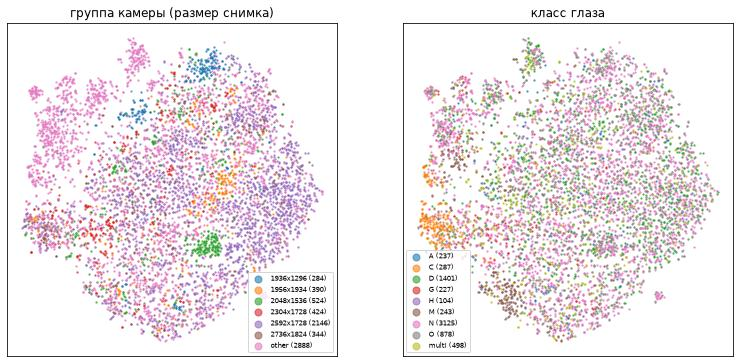

In [52]:
index = pd.read_csv(EMBEDDINGS_DIR / "resnet18" / "index.csv")
embeddings = np.load(EMBEDDINGS_DIR / "resnet18" / "embeddings.npy")
rows = data[["patient_id", "eye"]].merge(
    index.reset_index(), on=["patient_id", "eye"], how="left"
)["index"]
emb = embeddings[rows.to_numpy()]
reduced = PCA(50, random_state=SEED).fit_transform(emb)
xy = TSNE(2, init="pca", perplexity=30, random_state=SEED).fit_transform(reduced)

eye_class = data[EYE_LABELS].idxmax(axis=1).str[-1].where(single, "multi")
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for ax, column, title in [
    (axes[0], data["camera"], "группа камеры (размер снимка)"),
    (axes[1], eye_class, "класс глаза"),
]:
    for value in sorted(column.unique()):
        m = (column == value).to_numpy()
        ax.scatter(xy[m, 0], xy[m, 1], s=2, label=f"{value} ({m.sum()})", alpha=0.6)
    ax.set_title(title)
    ax.legend(markerscale=5, fontsize=7)
    ax.set_xticks([])
    ax.set_yticks([])
save_figure(fig, "eda_tsne");

In [53]:
knn = make_pipeline(StandardScaler(), KNeighborsClassifier(15))
groups_cv = GroupKFold(5)
scores = {
    "camera (7 groups)": cross_val_score(
        knn,
        emb,
        data["camera"],
        groups=data["patient_id"],
        cv=groups_cv,
        scoring="balanced_accuracy",
    ),
    "white background": cross_val_score(
        knn,
        emb,
        data["background"],
        groups=data["patient_id"],
        cv=groups_cv,
        scoring="balanced_accuracy",
    ),
    "eye class (single-label eyes, 8)": cross_val_score(
        knn,
        emb[single.to_numpy()],
        eye_class[single],
        groups=data.loc[single, "patient_id"],
        cv=groups_cv,
        scoring="balanced_accuracy",
    ),
}
print(
    pd.DataFrame(
        {
            k: {"balanced_acc": v.mean(), "chance": 1 / n}
            for (k, v), n in zip(scores.items(), [7, 2, 8])
        }
    ).T.round(3)
)
white = data[data["background"] == "white"]
print(
    f"white background eyes: {len(white)}, size {white['size'].unique().tolist()}, circle cut by the frame: {white['fundus_cut'].mean():.0%} (all eyes: {data['fundus_cut'].mean():.0%}), with C: {int(white['eye_C'].sum())}"
)

                                  balanced_acc  chance
camera (7 groups)                        0.559   0.143
white background                         0.758   0.500
eye class (single-label eyes, 8)         0.336   0.125
white background eyes: 15, size ['2464x1632'], circle cut by the frame: 0% (all eyes: 17%), with C: 12


**Результат:** на t-SNE видны плотные кластеры отдельных камер (1936×1296, 2048×1536, 2304×1728, 1956×1934). По классам отдельно выделяются только C и M, остальные классы перемешаны. kNN по эмбеддингам:
- камера (7 групп) предсказывается намного выше случайного уровня: balanced accuracy 0.56 при 0.14;
- класс глаза (8 классов, только глаза с одной меткой) - 0.34 при 0.125;
- белый фон - 0.76 при 0.5, хотя белый фон перед извлечением эмбеддингов закрашен в чёрный. Результат шумный: снимков с белым фоном всего 15 (одна камера 2464×1632, круг не обрезан, 12 из 15 - катаракта). Предположение: узнаются цвет и мутность снимков этой камеры и самой болезни, а не фон.

**Вывод:** гипотеза подтверждается частично. Даже после канонической обработки камера хорошо предсказывается по замороженным ImageNet-эмбеддингам, значит линейная голова на них может использовать признаки камеры. Утверждать, что камеру они кодируют сильнее, чем болезнь, по этим метрикам нельзя: у задач разное число классов и разная трудность. Это аргумент попробовать дообучение backbone, но не доказательство, что оно поможет. Проверка для следующих моделей: повторить этот kNN-тест на их эмбеддингах.

## 5. Геометрия

### 5.1. Отражение

**Гипотеза:** отражённый левый глаз выглядит как правый.

**Зачем:** от этого зависит, можно ли отражать снимки при обучении модели на один глаз и как это делать для парной модели.

**Как проверяем:** левый глаз, он же отражённый, и правый глаз того же пациента для трёх здоровых пациентов.

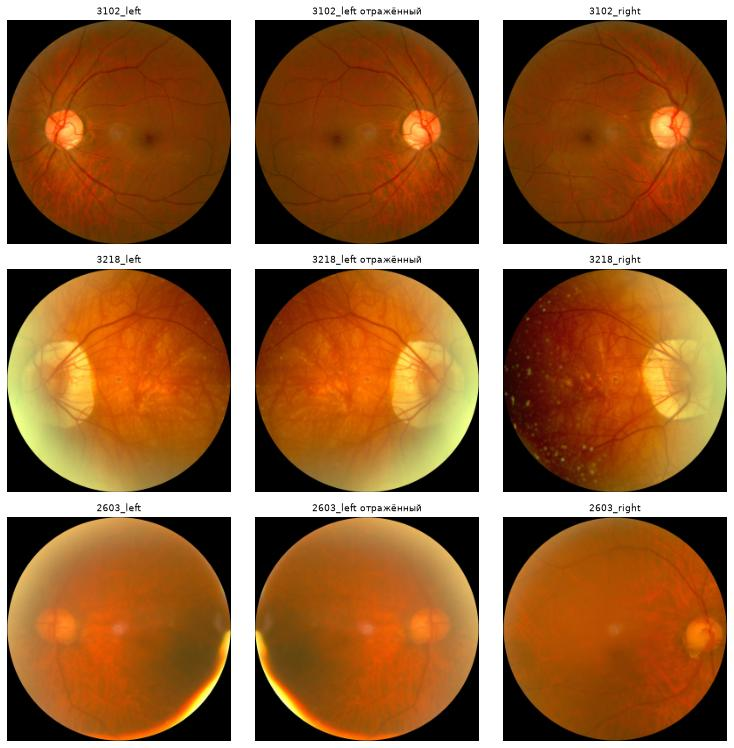

In [54]:
pair_ids = patients[(patients["N"] == 1)].sample(3, random_state=SEED).index
images, titles = [], []
for pid in pair_ids:
    left, right = (
        load_canonical(TRAIN_IMAGES_DIR / f"{pid}_left.jpg"),
        load_canonical(TRAIN_IMAGES_DIR / f"{pid}_right.jpg"),
    )
    images += [left, left[:, ::-1], right]
    titles += [f"{pid}_left", f"{pid}_left отражённый", f"{pid}_right"]
show_images(images, titles, ncols=3);

**Результат:** на показанных примерах отражённый левый глаз выглядит как правый: диск справа, сосудистые аркады расходятся так же. Но в [Kang et al., 2022](https://pmc.ncbi.nlm.nih.gov/articles/PMC8795182/) CNN отличала правые снимки ODIR от отражённых левых с точностью 91%: отражённый левый глаз - не точная копия правого.

**Открытый вопрос** (решать экспериментом, сравнив варианты на одной модели):
- **модель на один глаз:**
  - без отражения;
  - детерминированно отражать все левые глаза в ориентацию правых;
  - случайное горизонтальное отражение.

  Аргумент Kang et al. относится и ко второму, и к третьему варианту: в обоих случаях в одной ориентации оказываются настоящие правые и отражённые левые глаза.
- **парная модель:** если отражаем, то оба глаза сразу, и меняем их местами, чтобы позиции «левый/правый» не перепутались.

Вертикальное отражение в этом ноутбуке не проверяли.

### 5.2. Положение диска, повороты и масштаб

**Гипотеза:** положение диска на снимках разное; часть кругов обрезана кадром.

**Зачем:** аугментации поворота и обрезки не должны сильно выходить за то, что есть в данных; сильная обрезка может отрезать край, где бывают признаки болезни.

**Как проверяем:**
- **разброс положения диска** - угол линии «центр снимка - диск» к горизонтали и расстояние от центра до диска по нормальным глазам. Диск ищем как самое яркое пятно (`disc_x`, `disc_y`) и отбрасываем глаза, где он оказался не на своей стороне (детектор ошибся). Центр снимка - не fovea, а угол «диск - fovea» анатомически сам около -6…-8°, поэтому этот угол не равен повороту снимка;
- доля кругов, обрезанных кадром;
- примеры поворота на -15°, +15° и -30° и обрезки до 92% и 80% стороны (85% и 64% площади).

normal eyes: 2749; angle of the line image centre - disc to the horizontal, degrees, p10/p25/p50/p75/p90: [-20.7 -13.1  -6.5   0.    8.5]
disc distance from the centre (in image widths): p5/p50/p95 [0.11 0.24 0.36]
circle cut by the frame: 17.5%; fundus fraction of the frame p5/p50/p95 [0.42 0.47 0.79]


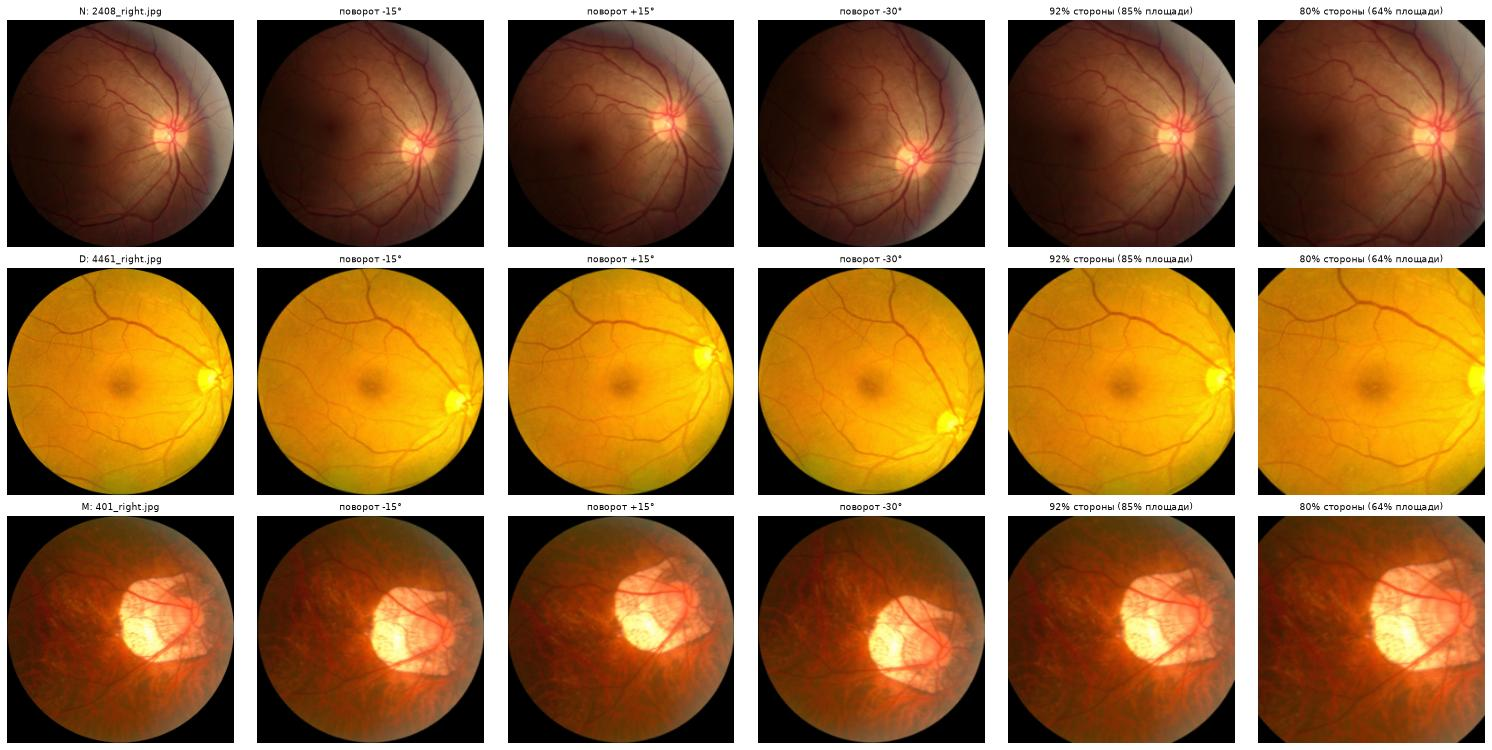

In [55]:
wrong_side = ((data["eye"] == "left") & (data["disc_x"] > 0.55)) | (
    (data["eye"] == "right") & (data["disc_x"] < 0.45)
)
bad_quality = data["keywords"].map(lambda kws: bool(QUALITY_KEYWORDS & set(kws)))
ok_disc = ~wrong_side & (data["eye_N"] == 1) & single & ~bad_quality
dx = np.where(data["eye"] == "left", 0.5 - data["disc_x"], data["disc_x"] - 0.5)
angle = np.degrees(np.arctan2(data["disc_y"] - 0.5, dx))[ok_disc]
print(
    f"normal eyes: {ok_disc.sum()}; angle of the line image centre - disc to the horizontal, degrees, p10/p25/p50/p75/p90: {np.percentile(angle, [10, 25, 50, 75, 90]).round(1)}"
)
print(
    f"disc distance from the centre (in image widths): p5/p50/p95 {np.percentile(np.hypot(dx, data['disc_y'] - 0.5)[ok_disc], [5, 50, 95]).round(2)}"
)
print(
    f"circle cut by the frame: {data['fundus_cut'].mean():.1%}; fundus fraction of the frame p5/p50/p95 {np.percentile(data['fundus_frac'], [5, 50, 95]).round(2)}"
)


def rotate(img: np.ndarray, degrees: float) -> np.ndarray:
    h, w = img.shape[:2]
    m = cv2.getRotationMatrix2D((w / 2, h / 2), degrees, 1.0)
    return cv2.warpAffine(img, m, (w, h), borderValue=0)


def center_crop(img: np.ndarray, frac: float) -> np.ndarray:
    h, w = img.shape[:2]
    ch, cw = int(h * frac), int(w * frac)
    top, left = (h - ch) // 2, (w - cw) // 2
    return cv2.resize(
        img[top : top + ch, left : left + cw], (w, h), interpolation=cv2.INTER_AREA
    )


examples = {
    c: data.loc[(data["eye_" + c] == 1) & single, "image"]
    .sample(1, random_state=SEED)
    .item()
    for c in ["N", "D", "M"]
}
images, titles = [], []
for c, name in examples.items():
    img = load_canonical(TRAIN_IMAGES_DIR / name)
    images += [
        img,
        rotate(img, -15),
        rotate(img, 15),
        rotate(img, -30),
        center_crop(img, 0.92),
        center_crop(img, 0.8),
    ]
    titles += [
        f"{c}: {name}",
        "поворот -15°",
        "поворот +15°",
        "поворот -30°",
        "92% стороны (85% площади)",
        "80% стороны (64% площади)",
    ]
show_images(images, titles, ncols=6);

**Результат:**
- **Положение диска** по 2749 нормальным глазам: медиана расстояния от центра 0.24 ширины снимка. Угол «центр - диск» - медиана -6.5°, p25-p75 от -13° до 0°, p10-p90 от -21° до +8.5°. Это разброс положения диска, в него входят и центровка снимка, и ошибки детектора; диапазон поворота из него не выводится.
- **Обрезанный круг:** у 17.5% снимков круг обрезан кадром сверху и снизу (диафрагма камеры).
- **Примеры:** поворот на ±15° выглядит естественно, на -30° - заметно неестественно. Обрезка до 92% стороны (85% площади) срезает край круга, до 80% стороны (64% площади) - большую часть периферии.

**Вывод:** диапазон поворота по этим данным не измерен. На просмотренных примерах ±15° выглядит естественно. Для кропа: `RandomResizedCrop(scale=...)` задаёт долю площади; `scale` 0.85 ≈ 92% по стороне. Уже при этом срезается край круга, где бывают признаки (лазерные следы, дистрофии), поэтому сильнее обрезать не стоит. Ещё `RandomResizedCrop` по умолчанию меняет соотношение сторон (`ratio` 3/4-4/3) и растягивает круг в овал, поэтому нужно `ratio=(1, 1)`.

## 6. Аугментации

### 6.1. Аугментации в статьях

**Гипотеза:** в статьях по ODIR и близким multilabel-датасетам используют похожую предобработку (обрезка поля зрения, resize) и стандартные аугментации, которые можно взять за основу.

| Статья | Данные | Предобработка | Аугментации (параметры) |
|---|---|---|---|
| Bhati et al., 2022. *Discriminative Kernel Convolution Network for Multi-Label Ophthalmic Disease Detection on Imbalanced Fundus Image Dataset* ([arXiv:2207.07918](https://arxiv.org/abs/2207.07918)) | ODIR-5K; метки разделены по глазам по keywords | обрезка поля зрения по первым нечёрным пикселям, 224×224 | отражение, масштаб 0.5 / 0.7 / 0.8 / 0.9, кроп, поворот, контраст, hue, saturation, gamma (диапазоны не указаны); over/undersampling классов |
| Rodríguez et al., 2022. *Multi-label Retinal Disease Classification Using Transformers* ([arXiv:2207.02335](https://arxiv.org/abs/2207.02335)) | MuReD (ARIA + STARE + RFMiD), не ODIR | обрезка поля зрения по красному каналу, 384×384; удалены 10% самых размытых снимков | по конфигурации победителя RIADD: HorizontalFlip p=0.5, VerticalFlip p=0.5, Rotate ±30° p=0.5, MedianBlur 7 p=0.3, GaussNoise p=0.5 (параметр в таблице неоднозначен), HueSaturationValue ±10 p=0.3, RandomBrightnessContrast ±0.2 p=0.3, Cutout 5×(20×20) p=0.5 |
| Gholizadeh, Rezapour, 2025. *Robust Multi-Disease Retinal Classification via Xception-Based Transfer Learning and W-Net Vessel Segmentation* ([arXiv:2512.10608](https://arxiv.org/abs/2512.10608)) | ODIR-5K + другие датасеты | обрезка ROI по контуру, resize 224 или 299, нормализация яркости методом Graham (вычитание размытого снимка) | случайное горизонтальное отражение, случайный сдвиг (параметры не указаны) |
| Karthikayan et al., 2024. *Explainable AI: Comparative Analysis of Normal and Dilated ResNet Models for Fundus Disease Classification* ([arXiv:2407.05440](https://arxiv.org/abs/2407.05440)) | ODIR-5K | resize 224×224 | не указаны |
| Kang et al., 2022. *Asymmetry between right and left fundus images identified using convolutional neural networks*, Sci Rep 12:1444 ([PMC8795182](https://pmc.ncbi.nlm.nih.gov/articles/PMC8795182/)) | ODIR + данные клиники | обрезка до круга, 299×299 | исследование отражения: CNN отличает правые снимки ODIR от отражённых левых с точностью 91.1%; авторы советуют осторожно применять flip |

**Вывод и что делаем:**
- Общая схема в статьях: обрезка поля зрения → 224-384 px; отражения; поворот до ±30°; мягкие изменения цвета и яркости (±0.2, ±10); размытие и шум с малой вероятностью.
- Это совпадает с нашей предобработкой (`to_canonical`).
- Параметры кропа, цвета, яркости и размытия берём по нашим данным (5.2, 6.2-6.4), а не из статей; диапазон поворота по данным не измерен (5.2); вертикальное отражение в этом ноутбуке не проверяли (см. 5.1).

### 6.2. Яркость и контраст

**Гипотеза:** яркость и контраст между снимками заметно различаются, а среднее и std каналов глазного дна отличаются от ImageNet.

**Зачем:** аугментации должны покрывать реальный разброс, но не сильно больше; нормализация влияет на дообучение предобученной модели.

**Как проверяем:** средние и std каналов внутри маски, объединённые по всем пикселям глазного дна (взвешены по площади маски); перцентили медианной яркости и контраста; отношения p5/p50 и p95/p50 как диапазон множителей.

inside the fundus mask, 0-1 scale
    mean    std  imagenet_mean  imagenet_std
r  0.551  0.197          0.485         0.229
g  0.349  0.163          0.456         0.224
b  0.191  0.134          0.406         0.225
     gray_p50  contrast  mean_r  mean_g  mean_b
p5       49.0      13.0    78.8    43.3     5.8
p25      76.0      19.5   116.1    67.2    27.0
p50      96.0      24.5   142.1    88.5    47.5
p75     120.0      30.2   167.8   112.3    69.2
p95     154.0      41.7   202.6   145.5    99.3
brightness factor p5/p50, p95/p50: [0.51, 1.6]
contrast factor p5/p50, p95/p50: [0.53, 1.7]


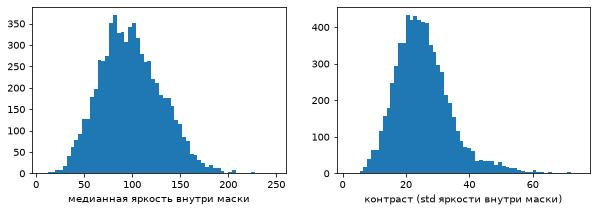

In [56]:
pixels = data["fundus_frac"] * data["width"] * data["height"]
pooled = {}
for c in "rgb":
    mean = np.average(data[f"mean_{c}"], weights=pixels)
    second = np.average(data[f"std_{c}"] ** 2 + data[f"mean_{c}"] ** 2, weights=pixels)
    pooled[c] = {"mean": mean / 255, "std": np.sqrt(second - mean**2) / 255}
pooled = pd.DataFrame(pooled).T
pooled["imagenet_mean"] = [0.485, 0.456, 0.406]
pooled["imagenet_std"] = [0.229, 0.224, 0.225]
print("inside the fundus mask, 0-1 scale")
print(pooled.round(3))

spread = pd.DataFrame(
    {
        col: np.percentile(data[col], [5, 25, 50, 75, 95])
        for col in ["gray_p50", "contrast", "mean_r", "mean_g", "mean_b"]
    },
    index=["p5", "p25", "p50", "p75", "p95"],
)
print(spread.round(1))
print(
    "brightness factor p5/p50, p95/p50:",
    (spread.loc[["p5", "p95"], "gray_p50"] / spread.loc["p50", "gray_p50"])
    .round(2)
    .tolist(),
)
print(
    "contrast factor p5/p50, p95/p50:",
    (spread.loc[["p5", "p95"], "contrast"] / spread.loc["p50", "contrast"])
    .round(2)
    .tolist(),
)

fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].hist(data["gray_p50"], bins=60)
axes[0].set_xlabel("медианная яркость внутри маски")
axes[1].hist(data["contrast"], bins=60)
axes[1].set_xlabel("контраст (std яркости внутри маски)")
save_figure(fig, "eda_brightness_contrast");

**Результат:**
- **Каналы.** Внутри маски среднее (0.551, 0.349, 0.191) и std (0.197, 0.163, 0.134) по RGB; у ImageNet (0.485, 0.456, 0.406) и (0.229, 0.224, 0.225). Глазное дно сильно краснее, синего канала почти нет, разброс меньше.
- **Разброс яркости:** медианная яркость p5 49, p50 96, p95 154 - множители 0.51-1.60 (межквартильный размах 0.79-1.25).
- **Разброс контраста:** p5 13, p50 24.5, p95 41.7 - множители 0.53-1.70.

**Вывод и что делаем:**
- Для предобученных ImageNet-моделей оставляем нормализацию ImageNet (`IMAGENET_MEAN/STD` в `src/data/datasets.py`): это стандартная практика для предобученных моделей; свои mean/std можно сравнить экспериментом. Свои mean/std (с учётом чёрных углов квадрата ~21% площади) имеет смысл брать только при обучении с нуля.
- Аугментации яркости и контраста: множители примерно ×[0.75, 1.3] (покрывают межквартильный размах; крайние 5% - это как раз тёмные и пересвеченные снимки, в том числе катаракта, их не имитируем).

### 6.3. Цвет

**Гипотеза:** сильное изменение цвета портит признаки болезней, мягкое - нет.

**Зачем:** катаракта - мутный желтоватый снимок, при диабете и гипертонии важен цвет сосудов и кровоизлияний.

**Как проверяем:** снимки с C, D и H (глаза с одной меткой) до и после сдвига тона (hue в единицах OpenCV 0-179: +4 ≈ 8°, +10 ≈ 20°), насыщенности ×0.7/×1.3 и яркости ×0.7.

hue of the mean fundus colour inside the mask by camera, OpenCV units (0-179):
            p25   p50   p75
camera                     
2592x1728  11.0  13.0  15.0
2048x1536  14.0  17.0  20.0
2304x1728  11.0  13.0  17.0
1956x1934   9.0  11.0  12.0
2736x1824  14.0  16.0  18.0
1936x1296   9.0  10.0  11.0
other      11.0  13.0  15.0
all eyes: p5/p25/p50/p75/p95 = [8.0, 11.0, 13.0, 15.0, 20.0]; camera medians 10-17


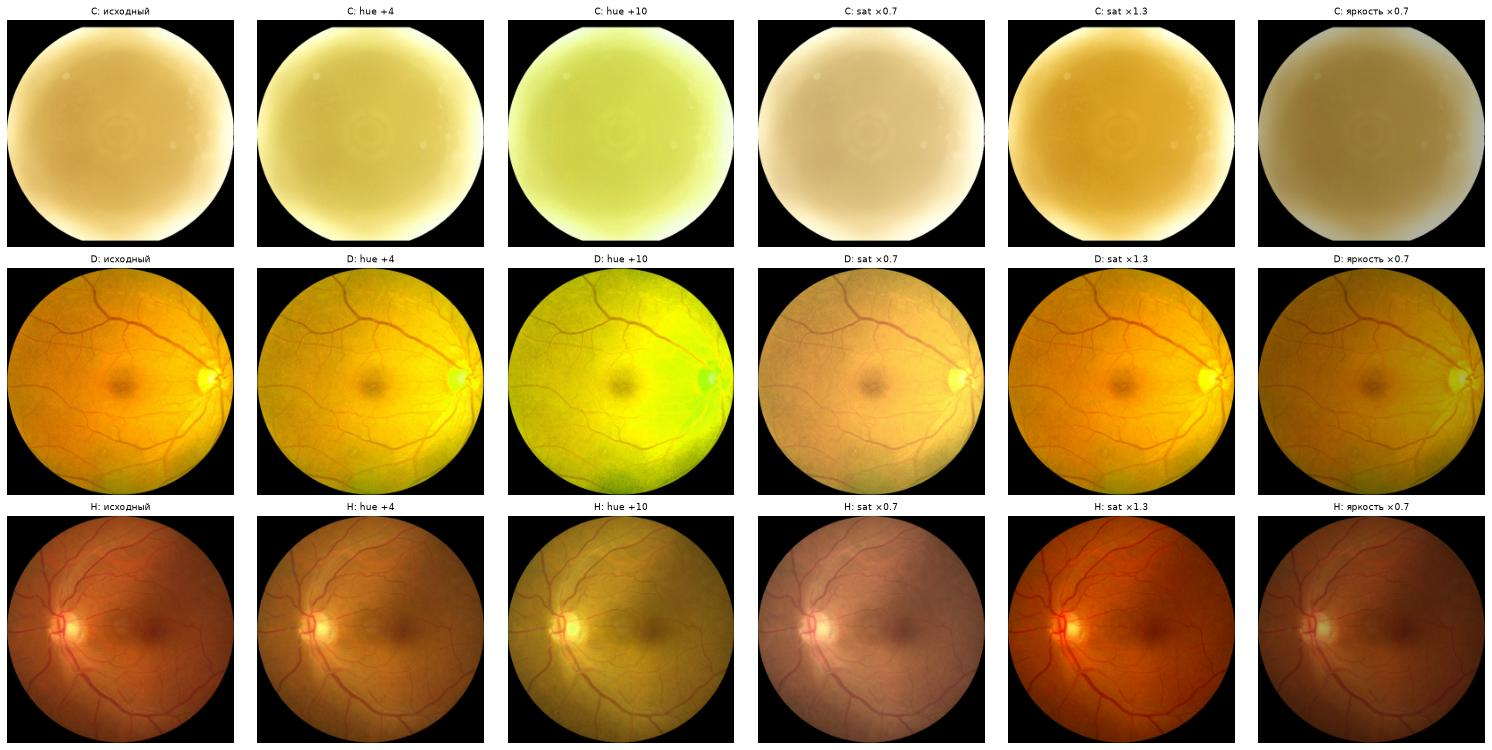

In [57]:
def color_jitter(
    img: np.ndarray, hue: int = 0, sat: float = 1.0, val: float = 1.0
) -> np.ndarray:
    hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV).astype(np.float32)
    hsv[..., 0] = (hsv[..., 0] + hue) % 180
    hsv[..., 1] = np.clip(hsv[..., 1] * sat, 0, 255)
    hsv[..., 2] = np.clip(hsv[..., 2] * val, 0, 255)
    return cv2.cvtColor(hsv.astype(np.uint8), cv2.COLOR_HSV2RGB)


mean_rgb = np.clip(data[["mean_r", "mean_g", "mean_b"]].to_numpy(), 0, 255).astype(
    np.uint8
)[None]
data["hue"] = cv2.cvtColor(mean_rgb, cv2.COLOR_RGB2HSV)[0, :, 0]
hue_by_camera = (
    data.groupby("camera")["hue"].quantile([0.25, 0.5, 0.75]).unstack().loc[CAMERAS]
)
hue_by_camera.columns = ["p25", "p50", "p75"]
print("hue of the mean fundus colour inside the mask by camera, OpenCV units (0-179):")
print(hue_by_camera)
print(
    f"all eyes: p5/p25/p50/p75/p95 = {np.percentile(data['hue'], [5, 25, 50, 75, 95]).tolist()}; camera medians {hue_by_camera['p50'].min():.0f}-{hue_by_camera['p50'].max():.0f}"
)


examples = {
    c: data.loc[(data["eye_" + c] == 1) & single, "image"]
    .sample(1, random_state=SEED)
    .item()
    for c in ["C", "D", "H"]
}
variants = [
    ("исходный", {}),
    ("hue +4", {"hue": 4}),
    ("hue +10", {"hue": 10}),
    ("sat ×0.7", {"sat": 0.7}),
    ("sat ×1.3", {"sat": 1.3}),
    ("яркость ×0.7", {"val": 0.7}),
]
images, titles = [], []
for c, name in examples.items():
    img = load_canonical(TRAIN_IMAGES_DIR / name)
    for title, params in variants:
        images.append(color_jitter(img, **params))
        titles.append(f"{c}: {title}")
show_images(images, titles, ncols=6);

**Результат:**
- **Тон по камерам.** Тон среднего цвета глазного дна (hue, единицы OpenCV) по всем глазам: p25-p75 от 11 до 15, p5-p95 от 8 до 20. Медианы камер - от 10 до 17.
- **Сдвиги на примерах:**
  - hue +4 меньше разницы между медианами камер (7) и равен межквартильному размаху;
  - hue +10 уводит медианный снимок (13) за p95 (20). На примерах снимки становятся неестественно зелёными (D) или розовыми, у катаракты меняется желтоватый оттенок;
  - насыщенность ×0.7-1.3: сосуды и кровоизлияния остаются различимы;
  - яркость ×0.7 близка к реальным тёмным снимкам.

**Вывод и что делаем:**
- hue не больше ±4 по OpenCV (±0.02 в долях круга, как в torchvision `ColorJitter(hue=0.02)`) - в пределах реального разброса тона между снимками и камерами;
- насыщенность ×[0.7, 1.3] (по примерам), яркость и контраст ×[0.75, 1.3] (6.2);
- сдвиг тона больше реального разброса (как +10) не используем.

### 6.4. Размытие и шум

**Гипотеза:** размытие и шум имитируют плохие снимки, но сильное размытие делает здоровый снимок похожим на катаракту.

**Зачем:** катаракта на снимке - это размытие и мутность; размытый здоровый снимок может запутать модель.

**Как проверяем:** медианная резкость по классам (глаза с одной меткой), распределение резкости N и C; здоровые снимки с размытием σ=1.5 и 3 (на 256×256) и гауссовым шумом σ=15 рядом со снимками с катарактой.

N    23.4
D    26.9
G    17.6
C    10.5
A    24.3
H    32.3
M    20.7
O    22.6
Name: median sharpness, single-label eyes, dtype: float64
quality keywords: 16.8


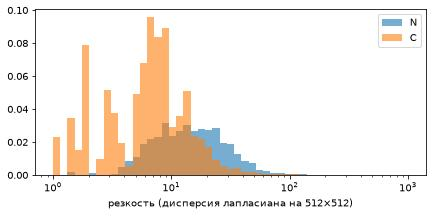

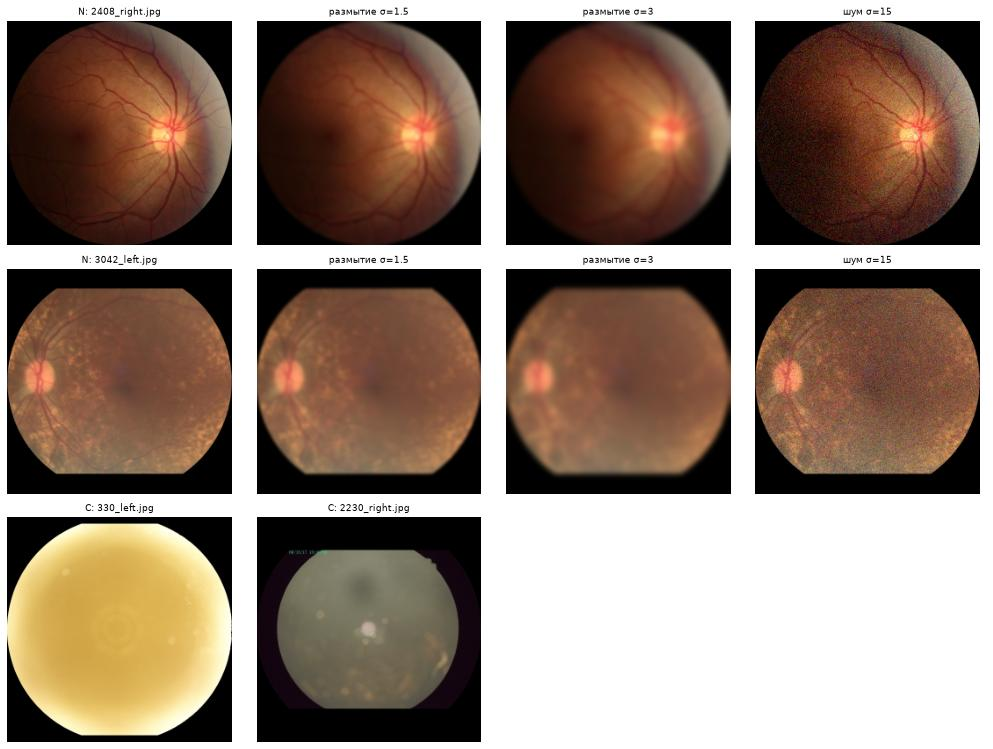

In [58]:
sharp = pd.Series(
    {
        c: data.loc[(data["eye_" + c] == 1) & single, "sharpness"].median()
        for c in LABELS
    },
    name="median sharpness, single-label eyes",
)
print(sharp.round(1))
print("quality keywords:", round(data.loc[bad_quality, "sharpness"].median(), 1))

fig, ax = plt.subplots(figsize=(7, 3))
bins = np.logspace(0, 3, 50)
for c in ["N", "C"]:
    ax.hist(
        data.loc[(data["eye_" + c] == 1) & single, "sharpness"],
        bins=bins,
        alpha=0.6,
        density=True,
        label=c,
    )
ax.set_xscale("log")
ax.set_xlabel("резкость (дисперсия лапласиана на 512×512)")
ax.legend()
save_figure(fig, "eda_sharpness_n_vs_c")


def gaussian_noise(img: np.ndarray, sigma: float) -> np.ndarray:
    noisy = img.astype(np.float32) + rng.normal(0, sigma, img.shape)
    return np.where(img.any(axis=2, keepdims=True), np.clip(noisy, 0, 255), 0).astype(
        np.uint8
    )


normal = (
    data.loc[(data["eye_N"] == 1) & single, "image"]
    .sample(2, random_state=SEED)
    .tolist()
)
cataract = (
    data.loc[(data["eye_C"] == 1) & single, "image"]
    .sample(2, random_state=SEED)
    .tolist()
)
images, titles = [], []
for name in normal:
    img = load_canonical(TRAIN_IMAGES_DIR / name)
    images += [
        img,
        cv2.GaussianBlur(img, (0, 0), 1.5),
        cv2.GaussianBlur(img, (0, 0), 3),
        gaussian_noise(img, 15),
    ]
    titles += [f"N: {name}", "размытие σ=1.5", "размытие σ=3", "шум σ=15"]
for name in cataract:
    images.append(load_canonical(TRAIN_IMAGES_DIR / name))
    titles.append(f"C: {name}")
show_images(images, titles, ncols=4);

**Результат:**
- **Резкость по классам:** медианная резкость C 10.5 против 23.4 у N - у C вдвое ниже, распределения N и C сильно расходятся. У снимков с keywords качества 16.8; самая высокая у H - 32.3.
- **Размытие:** на примерах при σ=3 здоровый снимок становится похож на лёгкую катаракту (сосуды исчезают), при σ=1.5 сосуды ещё видны.
- **Шум** σ=15 на примерах заметен, но на катаракту не похож.
- **Впечатанный текст:** на снимке катаракты `2230_right` в углу впечатаны дата и время.

**Вывод и что делаем:**
- низкая резкость - признак класса C, поэтому сильное размытие не используем; допустимо лёгкое (σ ≤ 1 на 224-384 px), на примерах при σ=1.5 сосуды ещё видны;
- небольшой гауссов шум (σ ≤ 10) на примерах не похож на признаки болезней.

**Открытые вопросы:**
- сколько снимков с впечатанным текстом и нужно ли его закрывать (в этом ноутбуке не считали);
- порог `sharpness` для проверки качества (3.1): по этим данным порог не выбран.

## 7. Итоги

**Что берём в обучение**
- Модель на один глаз учим на метках глаз `eye_*`, метку пациента получаем агрегацией по глазам. При копировании меток пациента у 31.6% глаз больных пациентов появляется лишняя болезнь (1.5).
- Multilabel: 8 сигмоид и BCE, у 16.7% пациентов 2+ болезни (1.3).
- Дисбаланс (H - 2.9% пациентов): macro PR-AUC с разбивкой по классам, `pos_weight`, сравнение по нескольким сидам (1.2).
- При разбиении по пациентам дубликаты (6 пар пациентов в Training Images) объединяем в одну группу (3.3).
- Вход канонический (`to_canonical`), качество моделей смотрим по группам камер (4.1, 4.2).
- Аугментации: `RandomResizedCrop(scale=(0.85, 1), ratio=(1, 1))`, поворот ±15° с чёрным заполнением, яркость и контраст ×[0.75, 1.3], насыщенность ×[0.7, 1.3], hue ≤ ±0.02, лёгкое размытие σ ≤ 1 и шум σ ≤ 10 (5.2, 6.2-6.4). Сильное размытие и сдвиг тона не используем: они похожи на признаки C или стирают их.
- Нормализация ImageNet (6.2).

**Открытые вопросы**
- ~30 нечитаемых глаз и 405 глаз с `lens dust`: исключать из лосса, оставлять или отсеивать проверкой качества (3.1).
- 16 пациентов с возрастом 1 год: исключить, считать пропуском или оставить (2.1).
- Отражение: без него, детерминированно левые в правые или случайное - решать экспериментом (5.1).
- Подавать ли в модель возраст и пол: C и G сильно связаны с возрастом, C и M чаще у женщин (2.2, 2.3). Сравнивать с моделью без них.
- Впечатанный текст на снимках и порог `sharpness` для проверки качества не изучены (6.4).

**Проблемы в данных**
- 14 пар снимков одного глаза под разными ID (9 пар пациентов, из них 13 пар - один и тот же снимок); у 398/668 и 706/89 разные возраст, пол или метки (3.3).
- 2 снимка - не глазное дно (`1706_left`, `1710_right`); `4580_left` помечен `no fundus image`, но это обычный снимок (3.2).
- 16 пациентов с возрастом 1 год (2.1).
- Распределение классов зависит от камеры (D 37% у 2592×1728 против ~22% у остальных, 12 из 15 снимков с белым фоном - C), а камера хорошо предсказывается по эмбеддингам ResNet18: потенциальный shortcut (4.1, 4.2).